# IEEE-CIS Fraud Detection: Exploratory Data Analysis

**Project:** real-time financial fraud detection, Phase 1, step 0 (run before `kaggle_train.py`)
**Data:** [IEEE-CIS Fraud Detection](https://www.kaggle.com/competitions/ieee-fraud-detection) on Kaggle: real e-commerce transactions provided by Vesta Corporation

This notebook checks the properties of the data that the fraud model depends on, before any model is trained. It answers five questions:

1. **How rare is fraud**, and what does that mean for evaluation?
2. **How does fraud change over time**, and how should the data be split?
3. **How much data is missing**, and does missingness itself carry signal?
4. **Which features separate fraud from non-fraud** on their own?
5. **Which features are redundant**, and which shift between the training and holdout periods?

Each section explains why the question matters, shows the chart, and prints the finding. Every number in a finding is computed from the data in the cell that prints it; none are typed by hand.

**Contents**

0. Setup
1. Dataset overview
2. Target: class imbalance
3. Time structure
4. Labeled train vs. unlabeled test
5. Time-based split
6. Missing values
7. Transaction amount
8. Categorical features
9. Single-feature signal
10. Redundant features
11. Distribution shift between core train and holdout (PSI)
12. Summary and handoff to training

**Outputs:** every figure is shown inline and saved as PNG to `eda_figures/`; a machine-readable summary is written to `eda_summary.json` (both under `/kaggle/working/` on Kaggle).

## 0. Setup

Libraries, data-path detection, one chart style for every figure, and small helpers. `wilson()` returns a 95% confidence interval for a fraud rate; unlike the normal approximation it stays reliable when rates or groups are small.

In [1]:
import os
import gc
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from scipy.stats import rankdata, ks_2samp
from IPython.display import display, Markdown

%matplotlib inline
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

SEED = 42
np.random.seed(SEED)

# Kaggle mounts the competition either directly under /kaggle/input or under
# /kaggle/input/competitions, depending on how the dataset was attached.
# IEEE_DATA_DIR can point to a local copy when running outside Kaggle.
_CANDIDATE_DIRS = [d for d in (os.environ.get("IEEE_DATA_DIR"),
                               "/kaggle/input/competitions/ieee-fraud-detection",
                               "/kaggle/input/ieee-fraud-detection") if d]
DATA_DIR = next((d for d in _CANDIDATE_DIRS
                 if os.path.exists(os.path.join(d, "train_transaction.csv"))), None)
assert DATA_DIR, f"train_transaction.csv not found in any of: {_CANDIDATE_DIRS}"
print("Data dir:", DATA_DIR)

WORK_DIR = ("/kaggle/working" if os.path.isdir("/kaggle/working")
            else os.environ.get("EDA_WORK_DIR", "eda_output"))
FIG_DIR = os.path.join(WORK_DIR, "eda_figures")
SUMMARY_PATH = os.path.join(WORK_DIR, "eda_summary.json")
Path(FIG_DIR).mkdir(parents=True, exist_ok=True)
SUMMARY = {"data_dir": DATA_DIR}

Data dir: /kaggle/input/competitions/ieee-fraud-detection


In [2]:
# ---- Chart style -----------------------------------------------------------
# Colour roles are fixed across the notebook:
#   blue   = transaction volume / non-fraud / single-series default
#   orange = fraud / fraud rate
#   aqua   = a second comparison series (always with a legend or label)
C = {
    "surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "axis": "#c3c2b7", "band": "#f0efec",
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "dark": "#1c5cab",
}
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#104281", "#3987e5", "#b7d3f6", "#f0efec", "#f5bebd", "#e34948", "#9e2222"])

plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "savefig.facecolor": C["surface"], "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": C["ink2"], "text.color": C["ink"],
    "axes.edgecolor": C["axis"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.7,
    "grid.linestyle": "-", "axes.axisbelow": True,
    "xtick.color": C["muted"], "ytick.color": C["muted"],
    "xtick.labelcolor": C["ink2"], "ytick.labelcolor": C["ink2"],
    "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 1.6, "lines.solid_capstyle": "round",
    "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.fontsize": 9,
    "axes.prop_cycle": plt.cycler(color=[C["blue"], C["orange"], C["aqua"]]),
})


# ---- Helpers ---------------------------------------------------------------
def titled(ax, title, sub=None):
    """Left-aligned title with an optional one-line subtitle under it."""
    ax.set_title(title, loc="left", pad=22 if sub else 8)
    if sub:
        ax.annotate(sub, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6),
                    textcoords="offset points", fontsize=9, color=C["ink2"], va="bottom")


def finish(fig, name):
    """Save the figure as PNG and show it inline."""
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()


def note(text):
    """Print a finding as formatted text."""
    display(Markdown(text))


def pct(x, d=2):
    return f"{x * 100:.{d}f}%"


def wilson(k, n, z=1.96):
    """Wilson score 95% interval for a proportion k / n (vectorised)."""
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


def rate_table(key, min_count=1):
    """Fraud rate per group: row count n, fraud count k, rate, Wilson interval."""
    if not isinstance(key, pd.Series):
        key = df[key]
    if not pd.api.types.is_numeric_dtype(key):
        key = key.astype("object").where(key.notna(), "(missing)")
    g = df.groupby(key, dropna=False)[TARGET].agg(n="size", k="sum")
    g = g[g["n"] >= min_count].copy()
    g["rate"] = g["k"] / g["n"]
    g["lo"], g["hi"] = wilson(g["k"], g["n"])
    return g


def rate_err(g):
    """Asymmetric error-bar lengths (in %) for a rate_table."""
    return np.vstack([np.maximum(g["rate"] - g["lo"], 0),
                      np.maximum(g["hi"] - g["rate"], 0)]) * 100


def feature_group(c):
    if c == "TransactionDT":
        return "Time"
    if c == "TransactionAmt":
        return "Amount"
    if c == "ProductCD":
        return "Product"
    if c.startswith("card"):
        return "Card"
    if c.startswith("addr"):
        return "Address"
    if c.startswith("dist"):
        return "Distance"
    if c.endswith("emaildomain"):
        return "Email"
    if c.startswith("id_") or c in ("DeviceType", "DeviceInfo"):
        return "Identity"
    if c[0] in "CDMV" and c[1:].isdigit():
        return c[0]
    return "Other"

## 1. Dataset overview

The data comes as two tables joined on `TransactionID`: **transactions** (one row per transaction, with the `isFraud` label) and **identity** (device and network data, available for only some transactions). Identity is left-joined onto transactions, the same join the training pipeline uses. Floats are downcast to float32 to save memory, and rows are sorted by time.

In [3]:
txn = pd.read_csv(os.path.join(DATA_DIR, "train_transaction.csv"))
idn = pd.read_csv(os.path.join(DATA_DIR, "train_identity.csv"))
shapes = {"train_transaction": txn.shape, "train_identity": idn.shape}
print(f"train_transaction: {txn.shape} | train_identity: {idn.shape}")

# Identity coverage BEFORE merging (how many transactions have an identity record).
identity_coverage = txn["TransactionID"].isin(idn["TransactionID"]).mean()
idn_ids = idn["TransactionID"].to_numpy()

df = txn.merge(idn, how="left", on="TransactionID")
del txn, idn
gc.collect()

fc = df.select_dtypes(include=["float64"]).columns
df[fc] = df[fc].astype(np.float32)
df = df.sort_values("TransactionDT", kind="mergesort").reset_index(drop=True)
HAS_ID = df["TransactionID"].isin(idn_ids).to_numpy()
del idn_ids

TARGET = "isFraud"
# Text columns by stored type (works for both object and pandas string dtypes).
CAT_COLS = sorted(c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]))
NUM_COLS = [c for c in df.columns if c not in CAT_COLS + [TARGET, "TransactionID"]]
FEAT_COLS = [c for c in df.columns if c not in (TARGET, "TransactionID")]
y = df[TARGET].to_numpy()
mem_gb = df.memory_usage(deep=True).sum() / 1e9

SUMMARY["shape_merged"] = list(df.shape)
SUMMARY["identity_coverage"] = float(identity_coverage)
SUMMARY["n_numeric"] = len(NUM_COLS)
SUMMARY["n_categorical"] = len(CAT_COLS)

overview = pd.Series({
    "train_transaction (rows x columns)": f"{shapes['train_transaction'][0]:,} x {shapes['train_transaction'][1]}",
    "train_identity (rows x columns)": f"{shapes['train_identity'][0]:,} x {shapes['train_identity'][1]}",
    "Merged (rows x columns)": f"{df.shape[0]:,} x {df.shape[1]}",
    "Transactions with an identity record": pct(identity_coverage),
    "Numeric columns (stored type)": f"{len(NUM_COLS)}",
    "Text columns (stored type)": f"{len(CAT_COLS)}",
    "Memory after float32 downcast": f"{mem_gb:.2f} GB",
}, name="value").to_frame()
display(overview)

train_transaction: (590540, 394) | train_identity: (144233, 41)


,value
train_transaction (rows x columns),"590,540 x 394"
train_identity (rows x columns),"144,233 x 41"
Merged (rows x columns),"590,540 x 434"
Transactions with an identity record,24.42%
Numeric columns (stored type),401
Text columns (stored type),31
Memory after float32 downcast,1.69 GB


### Feature groups

Most column meanings are masked by the data provider. The descriptions below are the ones published on the competition's data page.

In [4]:
GROUP_INFO = {
    "Time": "Seconds from an unknown reference datetime (a time delta, not a timestamp)",
    "Amount": "Transaction payment amount in USD",
    "Product": "Product code of the transaction",
    "Card": "Payment card information, e.g. card type, category, issuing bank, country",
    "Address": "Address (masked)",
    "Distance": "Distance (masked)",
    "Email": "Purchaser (P_) and recipient (R_) email domain",
    "C": "Counts, e.g. how many addresses are linked to the card (meaning masked)",
    "D": "Time deltas, e.g. days since the previous transaction",
    "M": "Match flags, e.g. whether the name on the card matches the address",
    "V": "Features engineered by Vesta: ranking, counting and other entity relations",
    "Identity": "Network connection and digital signature data (field names masked)",
}
guide = (pd.DataFrame({"column": FEAT_COLS})
         .assign(group=lambda d: d["column"].map(feature_group),
                 numeric=lambda d: d["column"].isin(NUM_COLS))
         .groupby("group", sort=False)
         .agg(columns=("column", "size"), stored_numeric=("numeric", "sum"),
              first=("column", "first"), last=("column", "last")))
guide["stored_text"] = guide["columns"] - guide["stored_numeric"]
guide["range"] = np.where(guide["columns"] > 1, guide["first"] + " ... " + guide["last"], guide["first"])
guide["description"] = guide.index.map(GROUP_INFO)
display(guide[["range", "columns", "stored_numeric", "stored_text", "description"]])

,range,columns,stored_numeric,stored_text,description
group,,,,,
Time,TransactionDT,1,1,0,Seconds from an unknown reference datetime (a ...
Amount,TransactionAmt,1,1,0,Transaction payment amount in USD
Product,ProductCD,1,0,1,Product code of the transaction
Card,card1 ... card6,6,4,2,"Payment card information, e.g. card type, cate..."
Address,addr1 ... addr2,2,2,0,Address (masked)
Distance,dist1 ... dist2,2,2,0,Distance (masked)
Email,P_emaildomain ... R_emaildomain,2,0,2,Purchaser (P_) and recipient (R_) email domain
C,C1 ... C14,14,14,0,"Counts, e.g. how many addresses are linked to ..."
D,D1 ... D15,15,15,0,"Time deltas, e.g. days since the previous tran..."


**Stored type vs. meaning.** The data page lists `ProductCD`, `card1`–`card6`, `addr1`–`addr2`, `P_emaildomain`, `R_emaildomain`, `M1`–`M9`, `DeviceType`, `DeviceInfo` and `id_12`–`id_38` as categorical. Several of these are stored as numbers (for example `card1` and `addr1`). This notebook splits columns by stored type, as the training pipeline does, and leaves number-coded categories out of analyses where numeric order would be meaningless (Section 9).

## 2. Target: class imbalance

The share of fraud decides how the model is evaluated and trained. When fraud is rare, accuracy is dominated by the majority class, so it can look excellent for a model that never flags a single fraud.

Fraud: 20,663 | Non-fraud: 569,877 | prevalence: 3.4990%


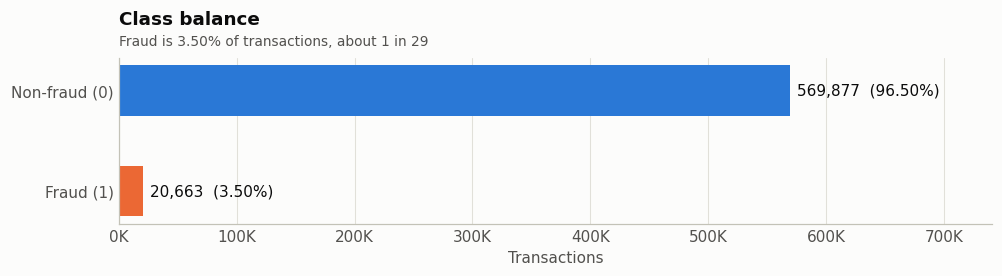

**Finding.** A model that predicts *non-fraud* for every transaction scores **96.50% accuracy** and catches no fraud at all. Accuracy is therefore uninformative here: the headline metric is PR-AUC (area under the precision-recall curve), and the rare class needs weighting during training.

In [5]:
prev = df[TARGET].mean()
counts = df[TARGET].value_counts()
n_fraud, n_legit = int(counts.get(1, 0)), int(counts.get(0, 0))
SUMMARY["fraud_prevalence"] = float(prev)
SUMMARY["baseline_accuracy_all_nonfraud"] = float(1 - prev)
print(f"Fraud: {n_fraud:,} | Non-fraud: {n_legit:,} | prevalence: {prev:.4%}")

fig, ax = plt.subplots(figsize=(9, 2.4))
vals = [n_legit, n_fraud]
bars = ax.barh(["Non-fraud (0)", "Fraud (1)"], vals, color=[C["blue"], C["orange"]], height=0.5)
for b, v in zip(bars, vals):
    ax.text(b.get_width() + max(vals) * 0.01, b.get_y() + b.get_height() / 2,
            f"{v:,}  ({v / len(df):.2%})", va="center", color=C["ink"])
ax.invert_yaxis()
ax.set_xlim(0, max(vals) * 1.3)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:,.0f}K"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Transactions")
titled(ax, "Class balance", f"Fraud is {prev:.2%} of transactions, about 1 in {1 / prev:.0f}")
finish(fig, "class_distribution.png")

note(f"**Finding.** A model that predicts *non-fraud* for every transaction scores "
     f"**{1 - prev:.2%} accuracy** and catches no fraud at all. Accuracy is therefore "
     f"uninformative here: the headline metric is PR-AUC (area under the precision-recall "
     f"curve), and the rare class needs weighting during training.")

## 3. Time structure

`TransactionDT` counts seconds from an unknown reference point. It gives order and spacing, not calendar dates. Three questions:

- Is the training period continuous, or does it have gaps?
- Is the fraud rate stable over time? If it drifts, a random train/test split would mix future patterns into training and overstate performance, so a time-based split is required.
- Are there daily or weekly cycles?

TransactionDT span: 1.0 -> 183.0 days (182 days)


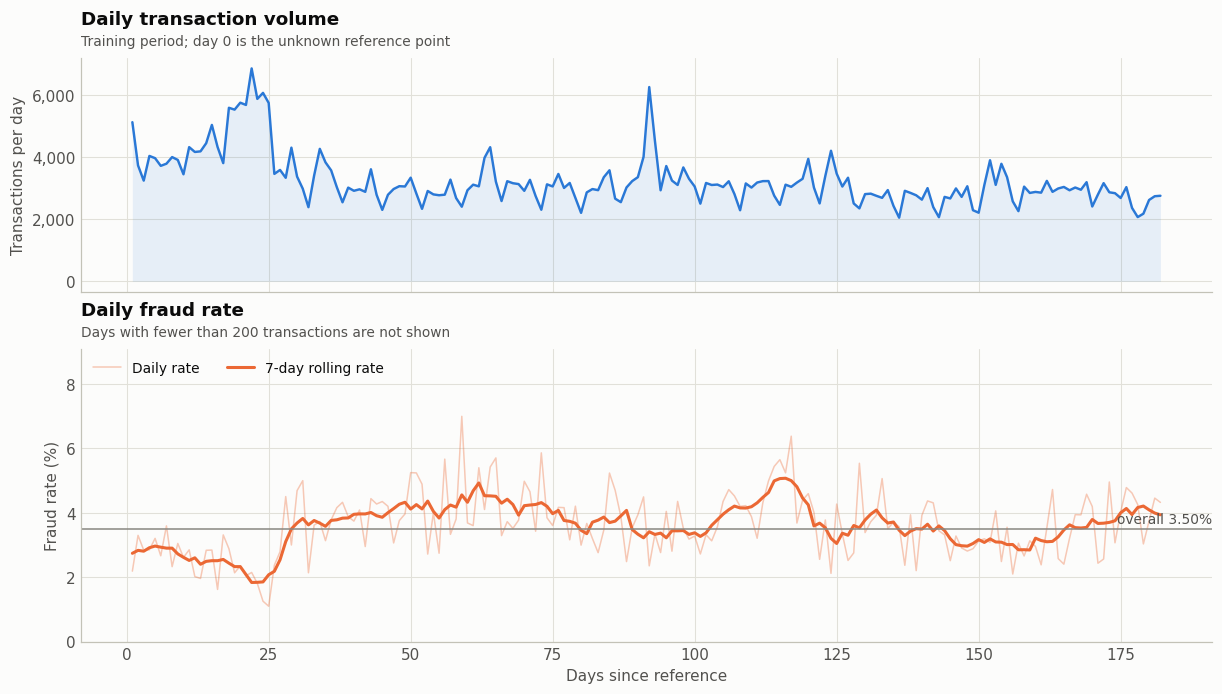

**Finding.** The training data covers **182 days**. The longest gap between consecutive transactions is **1.1 hours**, so the period has no gap of a day or more. Volume peaks on day 22 (6,852 transactions). The daily fraud rate ranges from **1.10% to 6.99%**; the 7-day rolling rate ranges from 1.83% to 5.07%.

In [6]:
dt_days = df["TransactionDT"] / 86400.0
SUMMARY["transactiondt"] = {
    "min_seconds": float(df["TransactionDT"].min()),
    "max_seconds": float(df["TransactionDT"].max()),
    "span_days": float(dt_days.max() - dt_days.min()),
}
print(f"TransactionDT span: {dt_days.min():.1f} -> {dt_days.max():.1f} days "
      f"({dt_days.max() - dt_days.min():.0f} days)")

day_bucket = dt_days.astype(int)
daily_all = df.groupby(day_bucket)[TARGET].agg(n="size", k="sum")
# Same definition as the training notes: drop near-empty day buckets (< 200 rows).
daily = df.groupby(day_bucket)[TARGET].agg(["mean", "size"])
daily = daily[daily["size"] >= 200]
roll = daily_all.rolling(7, center=True, min_periods=4).sum()
roll_rate = roll["k"] / roll["n"]

SUMMARY["daily_fraud_rate"] = {
    "min_pct": float(daily["mean"].min() * 100),
    "max_pct": float(daily["mean"].max() * 100),
}
max_gap_h = float(np.diff(df["TransactionDT"].to_numpy()).max() / 3600)
peak_day = int(daily_all["n"].idxmax())
SUMMARY["max_gap_within_train_hours"] = max_gap_h
SUMMARY["rolling7_fraud_rate_pct"] = {"min": float(roll_rate.min() * 100),
                                      "max": float(roll_rate.max() * 100)}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1.25]})
ax1.fill_between(daily_all.index, daily_all["n"], color=C["blue"], alpha=0.10, lw=0)
ax1.plot(daily_all.index, daily_all["n"], color=C["blue"])
ax1.set_ylabel("Transactions per day")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
titled(ax1, "Daily transaction volume", "Training period; day 0 is the unknown reference point")

ax2.plot(daily.index, daily["mean"] * 100, color=C["orange"], alpha=0.35, lw=1, label="Daily rate")
ax2.plot(roll_rate.index, roll_rate * 100, color=C["orange"], lw=2, label="7-day rolling rate")
ax2.axhline(prev * 100, color=C["muted"], lw=1)
ax2.annotate(f"overall {prev:.2%}", xy=(1, prev * 100), xycoords=("axes fraction", "data"),
             xytext=(0, 4), textcoords="offset points", ha="right", color=C["ink2"], fontsize=9)
ax2.set_ylim(0, daily["mean"].max() * 100 * 1.3)
ax2.set_ylabel("Fraud rate (%)")
ax2.set_xlabel("Days since reference")
ax2.legend(loc="upper left", ncol=2)
titled(ax2, "Daily fraud rate", "Days with fewer than 200 transactions are not shown")
finish(fig, "volume_and_fraud_rate_daily.png")

note(f"**Finding.** The training data covers **{dt_days.max() - dt_days.min():.0f} days**. "
     f"The longest gap between consecutive transactions is **{max_gap_h:.1f} hours**, so the period has "
     f"{'no gap of a day or more' if max_gap_h < 24 else 'at least one gap of a day or more'}. "
     f"Volume peaks on day {peak_day} ({daily_all['n'].max():,} transactions). "
     f"The daily fraud rate ranges from **{daily['mean'].min():.2%} to {daily['mean'].max():.2%}**; "
     f"the 7-day rolling rate ranges from {roll_rate.min():.2%} to {roll_rate.max():.2%}.")

### Weekly fraud rate with uncertainty

Daily rates are noisy. Weekly rates with 95% intervals separate real drift from sampling noise: if the fraud rate were constant, only about 1 week in 20 would have an interval that misses the overall rate.

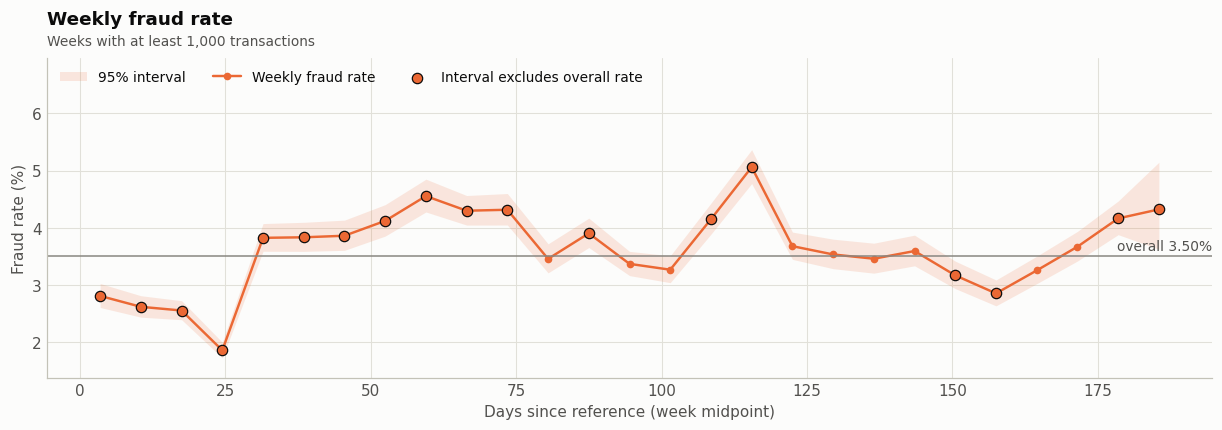

**Finding.** 18 of 27 weeks (67%) have a 95% interval that does not contain the overall rate, against about 5% expected if the rate were constant. Weekly rates range from 1.85% to 5.06%.

In [7]:
week = (dt_days // 7).astype(int)
wk = rate_table(week)
wk = wk[wk["n"] >= 1000]
excl = (wk["lo"] > prev) | (wk["hi"] < prev)
SUMMARY["weekly_fraud_rate"] = {
    "n_weeks": int(len(wk)), "weeks_interval_excludes_overall": int(excl.sum()),
    "min_pct": float(wk["rate"].min() * 100), "max_pct": float(wk["rate"].max() * 100),
}

fig, ax = plt.subplots(figsize=(11, 3.8))
x = wk.index.to_numpy() * 7 + 3.5
ex = excl.to_numpy()
ax.fill_between(x, wk["lo"] * 100, wk["hi"] * 100, color=C["orange"], alpha=0.15, lw=0,
                label="95% interval")
ax.plot(x, wk["rate"] * 100, color=C["orange"], marker="o", ms=4, label="Weekly fraud rate")
ax.scatter(x[ex], wk["rate"].to_numpy()[ex] * 100, s=46, facecolor=C["orange"],
           edgecolor=C["ink"], lw=0.8, zorder=3, label="Interval excludes overall rate")
ax.axhline(prev * 100, color=C["muted"], lw=1)
ax.annotate(f"overall {prev:.2%}", xy=(1, prev * 100), xycoords=("axes fraction", "data"),
            xytext=(0, 4), textcoords="offset points", ha="right", color=C["ink2"], fontsize=9)
ax.set_ylim(min(wk["lo"].min() * 100 * 0.8, prev * 100 * 0.8), wk["hi"].max() * 100 * 1.3)
ax.set_xlabel("Days since reference (week midpoint)")
ax.set_ylabel("Fraud rate (%)")
ax.legend(loc="upper left", ncol=3)
titled(ax, "Weekly fraud rate", "Weeks with at least 1,000 transactions")
finish(fig, "fraud_rate_weekly_ci.png")

note(f"**Finding.** {int(excl.sum())} of {len(wk)} weeks ({excl.mean():.0%}) have a 95% interval "
     f"that does not contain the overall rate, against about 5% expected if the rate were constant. "
     f"Weekly rates range from {wk['rate'].min():.2%} to {wk['rate'].max():.2%}.")

### Hour and weekday patterns

Hour = `(TransactionDT // 3600) % 24` and weekday = `(TransactionDT // 86400) % 7`. Because the reference point is unknown, hour 0 is not necessarily midnight and weekday 0 is not necessarily Monday; the shape of the pattern is what matters. A strong cycle makes time of day a candidate feature.

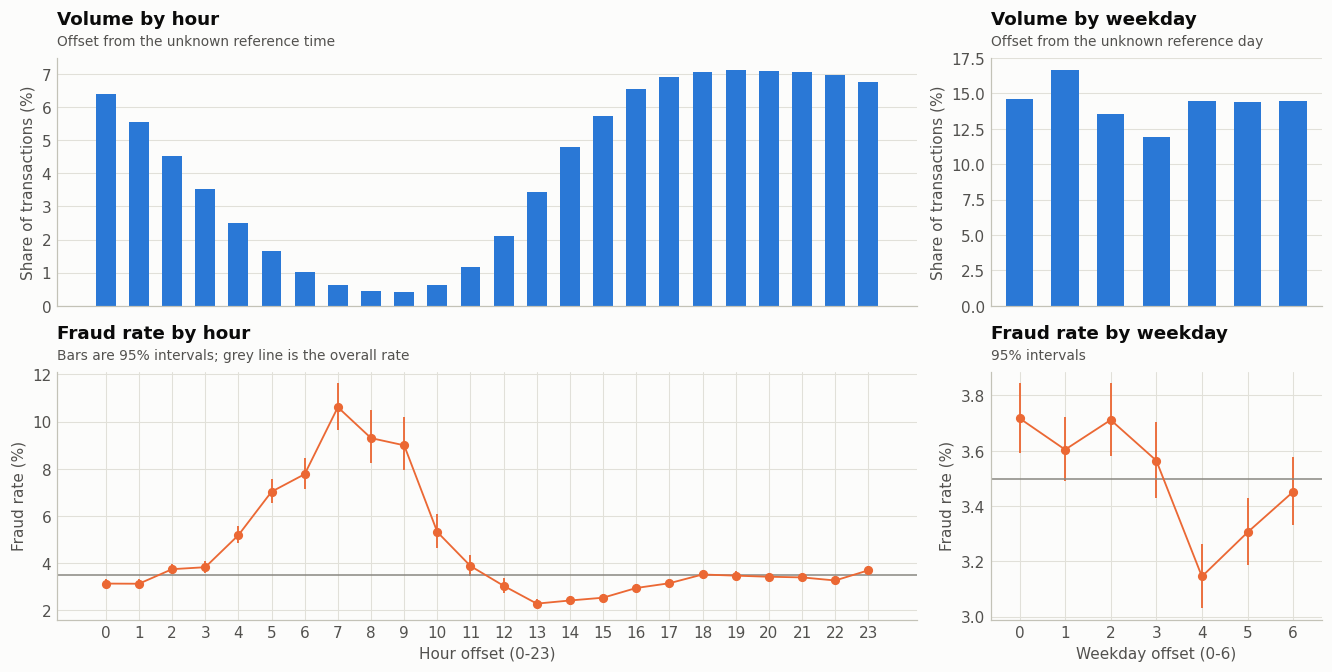

**Finding.** Fraud rate by hour ranges from **2.29% (hour 13)** to **10.61% (hour 7)**, a ratio of 4.6x. The quietest hour by volume is hour 9. By weekday the rate ranges from 3.15% to 3.72%.

In [8]:
hour = ((df["TransactionDT"] // 3600) % 24).astype(int)
wday = ((df["TransactionDT"] // 86400) % 7).astype(int)
h, w = rate_table(hour), rate_table(wday)

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex="col",
                         gridspec_kw={"width_ratios": [2.6, 1]})
for col, (g, lab) in enumerate([(h, "Hour offset (0-23)"), (w, "Weekday offset (0-6)")]):
    axv, axr = axes[0, col], axes[1, col]
    axv.bar(g.index, g["n"] / len(df) * 100, width=0.6, color=C["blue"])
    axv.set_ylabel("Share of transactions (%)")
    axv.grid(axis="x", visible=False)
    axr.errorbar(g.index, g["rate"] * 100, yerr=rate_err(g), fmt="o-", color=C["orange"],
                 ms=5, lw=1.2, elinewidth=1.2, capsize=0)
    axr.axhline(prev * 100, color=C["muted"], lw=1)
    axr.set_ylabel("Fraud rate (%)")
    axr.set_xlabel(lab)
    axr.set_xticks(g.index)
titled(axes[0, 0], "Volume by hour", "Offset from the unknown reference time")
titled(axes[0, 1], "Volume by weekday", "Offset from the unknown reference day")
titled(axes[1, 0], "Fraud rate by hour", "Bars are 95% intervals; grey line is the overall rate")
titled(axes[1, 1], "Fraud rate by weekday", "95% intervals")
finish(fig, "hour_weekday_patterns.png")

hmax, hmin = h["rate"].idxmax(), h["rate"].idxmin()
SUMMARY["hourly_fraud_rate"] = {
    "max_hour": int(hmax), "max_pct": float(h.loc[hmax, "rate"] * 100),
    "min_hour": int(hmin), "min_pct": float(h.loc[hmin, "rate"] * 100),
    "lowest_volume_hour": int(h["n"].idxmin()),
}
SUMMARY["weekday_fraud_rate_pct"] = {int(k): float(v * 100) for k, v in w["rate"].items()}
note(f"**Finding.** Fraud rate by hour ranges from **{h.loc[hmin, 'rate']:.2%} (hour {hmin})** to "
     f"**{h.loc[hmax, 'rate']:.2%} (hour {hmax})**, a ratio of {h.loc[hmax, 'rate'] / h.loc[hmin, 'rate']:.1f}x. "
     f"The quietest hour by volume is hour {h['n'].idxmin()}. "
     f"By weekday the rate ranges from {w['rate'].min():.2%} to {w['rate'].max():.2%}.")

## 4. Labeled train vs. unlabeled test

The competition's test files have no labels. In this project they serve only as replay traffic for Phase 2 (a simulated production stream), never for evaluation. This check confirms that they come strictly **after** the training period, so they behave like future traffic.

Train DT max: 15,811,131 | Test DT min: 18,403,224 | test strictly after train: True


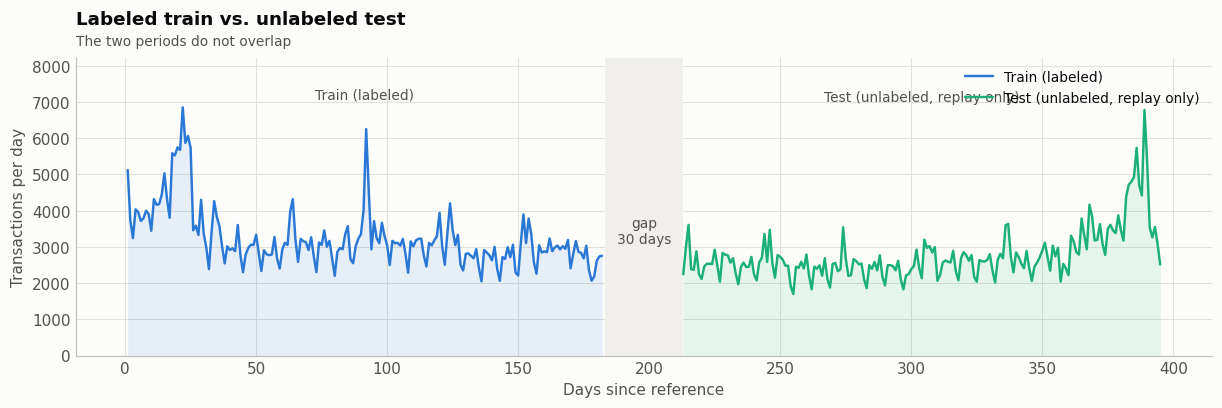

**Finding.** Test transactions start **30.0 days** after the last training transaction (strictly after: True). The test period has 506,691 transactions from day 213.0 to day 396.0.

In [9]:
test_dt = pd.read_csv(os.path.join(DATA_DIR, "test_transaction.csv"),
                      usecols=["TransactionDT"])["TransactionDT"]
SUMMARY["test_after_train"] = bool(test_dt.min() > df["TransactionDT"].max())
gap_days = (test_dt.min() - df["TransactionDT"].max()) / 86400
SUMMARY["train_test_gap_days"] = float(gap_days)
SUMMARY["test_rows"] = int(len(test_dt))
SUMMARY["test_span_days"] = [float(test_dt.min() / 86400), float(test_dt.max() / 86400)]
print(f"Train DT max: {df['TransactionDT'].max():,.0f} | "
      f"Test DT min: {test_dt.min():,.0f} | "
      f"test strictly after train: {SUMMARY['test_after_train']}")

tr_daily = day_bucket.value_counts().sort_index()
te_daily = (test_dt // 86400).astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 3.6))
for s, col, lab in [(tr_daily, C["blue"], "Train (labeled)"),
                    (te_daily, C["aqua"], "Test (unlabeled, replay only)")]:
    ax.fill_between(s.index, s.values, color=col, alpha=0.10, lw=0)
    ax.plot(s.index, s.values, color=col, label=lab)
    ax.annotate(lab, xy=(s.index.min() + (s.index.max() - s.index.min()) / 2, s.max()),
                xytext=(0, 6), textcoords="offset points", ha="center", color=C["ink2"], fontsize=9)
if gap_days > 0:
    ax.axvspan(df["TransactionDT"].max() / 86400, test_dt.min() / 86400, color=C["band"], lw=0)
    ax.text((df["TransactionDT"].max() + test_dt.min()) / 2 / 86400, max(tr_daily.max(), te_daily.max()) * 0.5,
            f"gap\n{gap_days:.0f} days", ha="center", va="center", color=C["ink2"], fontsize=9)
ax.set_ylim(0, max(tr_daily.max(), te_daily.max()) * 1.2)
ax.set_xlabel("Days since reference")
ax.set_ylabel("Transactions per day")
ax.legend(loc="upper right")
titled(ax, "Labeled train vs. unlabeled test", "The two periods do not overlap")
finish(fig, "train_vs_test_time.png")

note(f"**Finding.** Test transactions start **{gap_days:.1f} days** after the last training transaction "
     f"(strictly after: {SUMMARY['test_after_train']}). The test period has {len(test_dt):,} transactions "
     f"from day {test_dt.min() / 86400:.1f} to day {test_dt.max() / 86400:.1f}.")
del test_dt

## 5. Time-based split

The training notebook splits by time: the last 20% of rows (in time order) is the holdout, and the last 10% of the remaining rows is a validation slice used to tune the decision threshold. This section shows where the boundaries fall and the fraud rate in each segment.

Segment-level rates can be close even when daily rates drift, because drift averages out over long windows. The split matters anyway because feature distributions shift as well (Section 11).

core_train         rows= 425,188 fraud=3.515% days=[   1.0,  124.6]
validation_slice   rows=  47,244 fraud=3.501% days=[ 124.6,  141.1]
holdout            rows= 118,108 fraud=3.441% days=[ 141.1,  183.0]


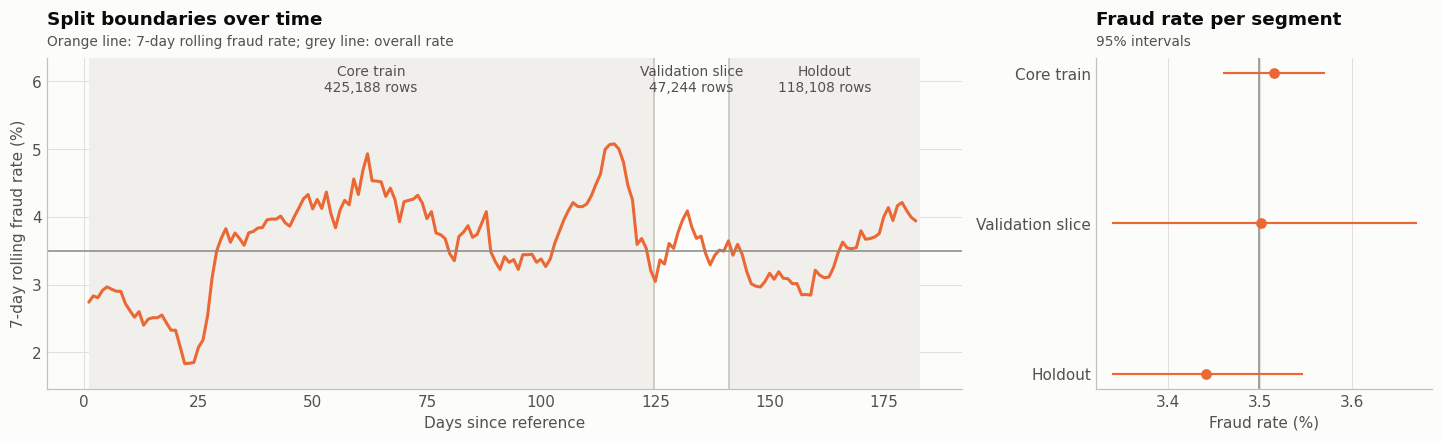

**Finding.** Segment fraud rates differ by at most **0.07 percentage points**, and their 95% intervals all overlap. At segment level the rate looks stable, so the case for the time split rests on drift in the daily rate (Section 3) and in feature distributions (Section 11).

In [10]:
n = len(df)
i_hold = int(n * 0.80)
i_val = int(i_hold * 0.90)
segs = {
    "core_train": (0, i_val),
    "validation_slice": (i_val, i_hold),
    "holdout": (i_hold, n),
}
SUMMARY["split_preview"] = {}
seg_rows = []
for name, (a, b) in segs.items():
    seg = df.iloc[a:b]
    k = int(seg[TARGET].sum())
    lo, hi = wilson(k, b - a)
    d0, d1 = float(seg["TransactionDT"].iloc[0] / 86400), float(seg["TransactionDT"].iloc[-1] / 86400)
    SUMMARY["split_preview"][name] = {"rows": int(b - a), "fraud_rate": float(seg[TARGET].mean()),
                                      "dt_days": [d0, d1]}
    seg_rows.append({"segment": name, "rows": b - a, "rate": k / (b - a), "lo": float(lo),
                     "hi": float(hi), "start": d0, "end": d1})
    print(f"{name:18s} rows={b - a:>8,} fraud={seg[TARGET].mean():.3%} days=[{d0:6.1f}, {d1:6.1f}]")
seg_tab = pd.DataFrame(seg_rows).set_index("segment")
labels = {"core_train": "Core train", "validation_slice": "Validation slice", "holdout": "Holdout"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [3, 1.1]})
for j, (name, r) in enumerate(seg_tab.iterrows()):
    ax1.axvspan(r["start"], r["end"], color=C["band"] if j % 2 == 0 else C["surface"], lw=0)
    ax1.annotate(f"{labels[name]}\n{int(r['rows']):,} rows", xy=((r["start"] + r["end"]) / 2, 1),
                 xycoords=("data", "axes fraction"), xytext=(0, -4), textcoords="offset points",
                 ha="center", va="top", fontsize=9, color=C["ink2"])
    if j > 0:
        ax1.axvline(r["start"], color=C["axis"], lw=1)
ax1.plot(roll_rate.index, roll_rate * 100, color=C["orange"], lw=2)
ax1.axhline(prev * 100, color=C["muted"], lw=1)
ax1.set_ylim(roll_rate.min() * 100 * 0.8, roll_rate.max() * 100 * 1.25)
ax1.set_xlabel("Days since reference")
ax1.set_ylabel("7-day rolling fraud rate (%)")
titled(ax1, "Split boundaries over time", "Orange line: 7-day rolling fraud rate; grey line: overall rate")

yy = np.arange(len(seg_tab))
ax2.errorbar(seg_tab["rate"] * 100, yy, xerr=rate_err(seg_tab), fmt="o", color=C["orange"],
             ms=6, elinewidth=1.4, capsize=0)
ax2.set_yticks(yy, [labels[s] for s in seg_tab.index])
ax2.invert_yaxis()
ax2.axvline(prev * 100, color=C["muted"], lw=1)
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("Fraud rate (%)")
titled(ax2, "Fraud rate per segment", "95% intervals")
finish(fig, "split_boundaries.png")

overlap = seg_tab["lo"].max() <= seg_tab["hi"].min()
spread_pp = (seg_tab["rate"].max() - seg_tab["rate"].min()) * 100
SUMMARY["split_rate_spread_pp"] = float(spread_pp)
SUMMARY["split_intervals_overlap"] = bool(overlap)
note(f"**Finding.** Segment fraud rates differ by at most **{spread_pp:.2f} percentage points**, and their "
     f"95% intervals {'all overlap' if overlap else 'do not all overlap'}. "
     + ("At segment level the rate looks stable, so the case for the time split rests on drift in the "
        "daily rate (Section 3) and in feature distributions (Section 11)." if overlap else
        "The fraud rate itself differs between segments, which the time split preserves."))

## 6. Missing values

Missingness in this dataset is heavy and structured: groups of columns are missing together, and identity columns exist only where an identity record exists. This section measures how much is missing and where, and whether missingness is related to fraud. That decides whether imputation alone is enough or whether the fact that a value is missing should be kept as information.

Columns >90% missing: 12 | >50% missing: 214 | fully observed: 18 (of 432)


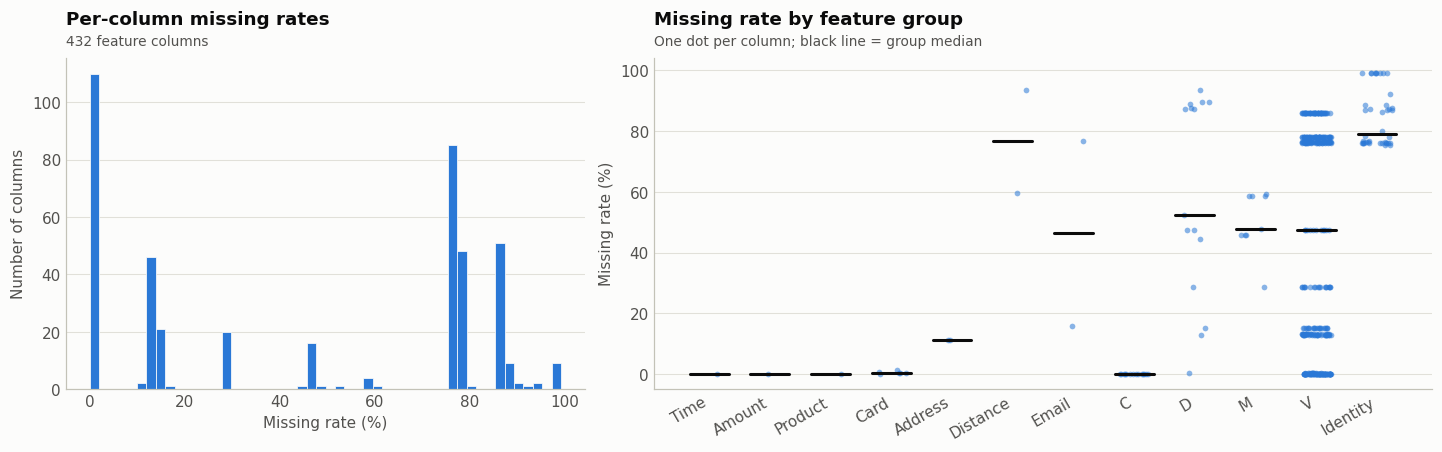

,id_24,id_25,id_07,id_08,id_21,id_26,id_23,id_27,id_22,dist2,D7,id_18,D13,D14,D12,id_03,id_04,D6,id_33,id_10
missing %,99.2,99.1,99.1,99.1,99.1,99.1,99.1,99.1,99.1,93.6,93.4,92.4,89.5,89.5,89.0,88.8,88.8,87.6,87.6,87.3


          group  n_cols  mean_missing_pct  n_numeric
     C (counts)      14               0.0         14
D (time deltas)      15              58.2         15
M (match flags)       9              49.9          0
 V (engineered)     339              43.0        339
id_* (identity)      38              84.8         23


**Finding.** 12 columns are more than 90% missing, 214 are more than 50% missing, and only 18 of 432 are fully observed. The most incomplete group is **Identity** (mean 84.5% missing per column).

In [11]:
miss = df.isna().mean().drop([TARGET, "TransactionID"]).sort_values(ascending=False)
SUMMARY["missingness"] = {
    "cols_over_90pct_missing": int((miss > 0.90).sum()),
    "cols_over_50pct_missing": int((miss > 0.50).sum()),
    "cols_fully_observed": int((miss == 0).sum()),
}
print(f"Columns >90% missing: {(miss > 0.90).sum()} | >50% missing: {(miss > 0.50).sum()} | "
      f"fully observed: {(miss == 0).sum()} (of {len(miss)})")

group_order = list(dict.fromkeys(feature_group(c) for c in FEAT_COLS))
mg = pd.DataFrame({"miss": miss, "group": [feature_group(c) for c in miss.index]})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.5]})
ax1.hist(miss * 100, bins=50, color=C["blue"], edgecolor=C["surface"], linewidth=0.5)
ax1.set_xlabel("Missing rate (%)")
ax1.set_ylabel("Number of columns")
ax1.grid(axis="x", visible=False)
titled(ax1, "Per-column missing rates", f"{len(miss)} feature columns")

rng = np.random.default_rng(SEED)
for i, gname in enumerate(group_order):
    v = mg.loc[mg["group"] == gname, "miss"].to_numpy() * 100
    ax2.scatter(i + rng.uniform(-0.25, 0.25, len(v)), v, s=14, color=C["blue"], alpha=0.55, lw=0)
    ax2.plot([i - 0.32, i + 0.32], [np.median(v)] * 2, color=C["ink"], lw=2)
ax2.set_xticks(range(len(group_order)), group_order, rotation=30, ha="right")
ax2.set_ylabel("Missing rate (%)")
ax2.grid(axis="x", visible=False)
titled(ax2, "Missing rate by feature group", "One dot per column; black line = group median")
finish(fig, "missingness_by_group.png")

display((miss.head(20) * 100).round(1).rename("missing %").to_frame().T)

# Group profile with the same definition and JSON key as the earlier version of this notebook.
fg_def = {
    "C (counts)": [c for c in df.columns if c.startswith("C") and c[1:].isdigit()],
    "D (time deltas)": [c for c in df.columns if c.startswith("D") and c[1:].isdigit()],
    "M (match flags)": [c for c in df.columns if c.startswith("M") and c[1:].isdigit()],
    "V (engineered)": [c for c in df.columns if c.startswith("V") and c[1:].isdigit()],
    "id_* (identity)": [c for c in df.columns if c.startswith("id_")],
}
SUMMARY["feature_groups"] = [
    {"group": g, "n_cols": len(cols), "mean_missing_pct": round(float(miss[cols].mean() * 100), 1),
     "n_numeric": len([c for c in cols if c in NUM_COLS])}
    for g, cols in fg_def.items()]
print(pd.DataFrame(SUMMARY["feature_groups"]).to_string(index=False))

grp_miss = mg.groupby("group")["miss"].mean().reindex(group_order) * 100
SUMMARY["missing_pct_by_group"] = {k: float(v) for k, v in grp_miss.items()}
worst = grp_miss.idxmax()
note(f"**Finding.** {(miss > 0.90).sum()} columns are more than 90% missing, {(miss > 0.50).sum()} are "
     f"more than 50% missing, and only {(miss == 0).sum()} of {len(miss)} are fully observed. "
     f"The most incomplete group is **{worst}** (mean {grp_miss[worst]:.1f}% missing per column).")

### Missingness pattern

Each row of the image is a transaction (an evenly spaced sample in time order), each column is a feature. Dark cells are missing values. Vertical bands that start and stop together are columns missing as a block; horizontal changes over time would show data collection changing during the period.

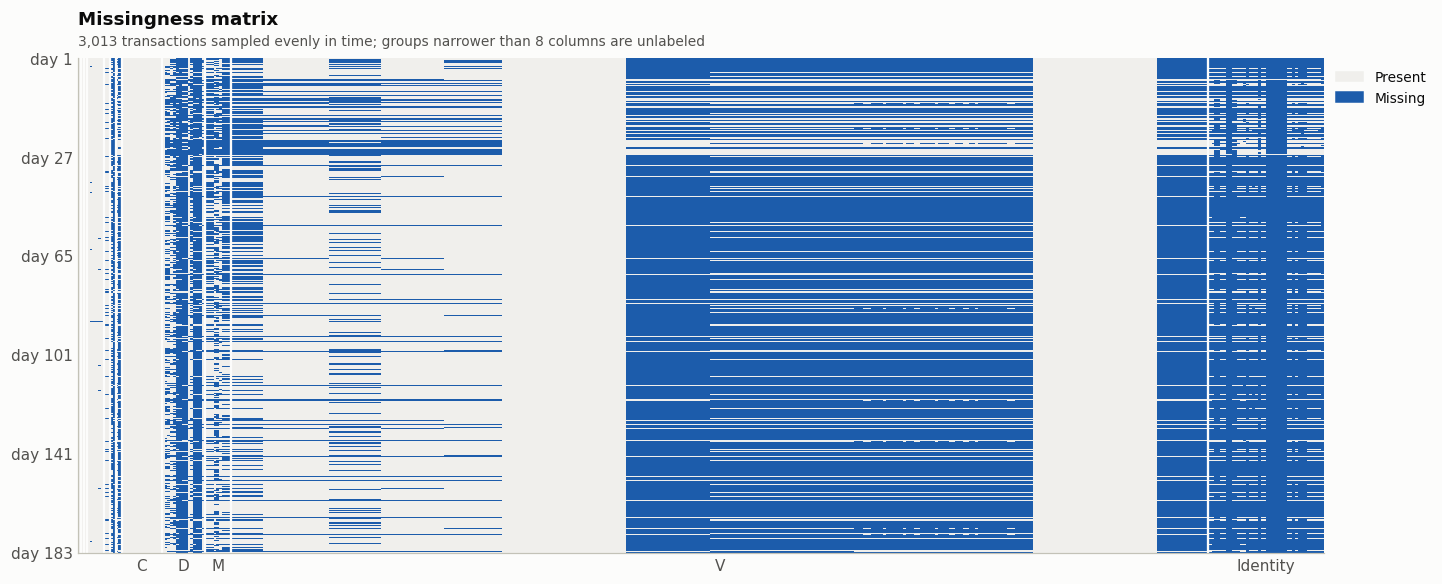

In [12]:
step = max(1, len(df) // 3000)
rows_idx = np.arange(0, len(df), step)
M = df.iloc[rows_idx][FEAT_COLS].isna().to_numpy()
groups_seq = [feature_group(c) for c in FEAT_COLS]
starts = [0] + [i for i in range(1, len(groups_seq)) if groups_seq[i] != groups_seq[i - 1]]
ends = starts[1:] + [len(groups_seq)]

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.imshow(M, aspect="auto", interpolation="nearest", cmap=ListedColormap([C["band"], C["dark"]]))
for s in starts[1:]:
    ax.axvline(s - 0.5, color=C["surface"], lw=1.5)
mids = [(s + e - 1) / 2 for s, e in zip(starts, ends)]
wide = [e - s >= 8 for s, e in zip(starts, ends)]
ax.set_xticks([m for m, ok in zip(mids, wide) if ok],
              [groups_seq[s] for s, ok in zip(starts, wide) if ok])
yt = np.linspace(0, len(rows_idx) - 1, 6).astype(int)
ax.set_yticks(yt, [f"day {dt_days.iloc[rows_idx[i]]:.0f}" for i in yt])
ax.grid(False)
ax.legend(handles=[Patch(color=C["band"], label="Present"), Patch(color=C["dark"], label="Missing")],
          loc="upper left", bbox_to_anchor=(1.0, 1.0))
titled(ax, "Missingness matrix", f"{len(rows_idx):,} transactions sampled evenly in time; "
       f"groups narrower than 8 columns are unlabeled")
finish(fig, "missingness_matrix.png")

### Is missingness related to fraud?

If the fraud rate differs between rows where a value is present and rows where it is missing, then missingness is itself informative. Median imputation alone erases that signal; a missing-value indicator, or a model that handles missing values natively, keeps it.

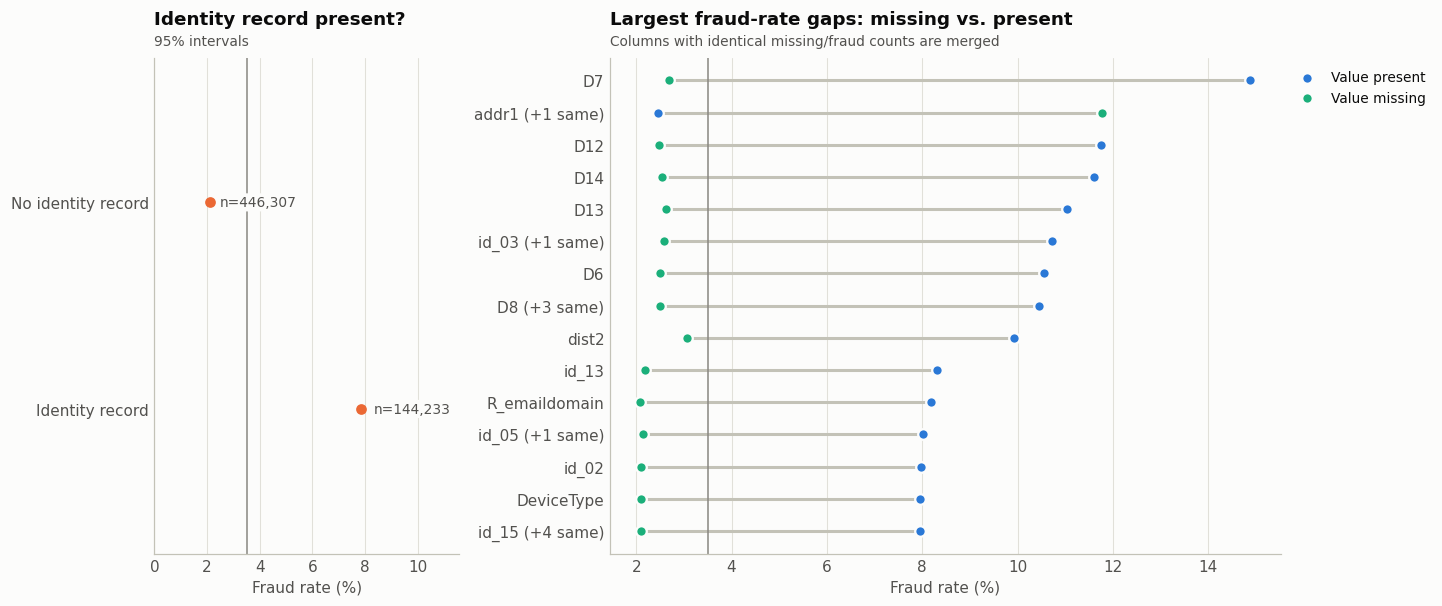

**Finding.** Transactions with an identity record have a fraud rate of **7.85%**, against **2.09%** without one (3.7x). The largest gap for a single column is `D7`: 2.70% fraud when missing vs. 14.88% when present. 304 of 339 testable columns show a gap above 1 percentage point (columns with fewer than 1,000 missing or present rows are not tested).

In [13]:
idg = rate_table(pd.Series(np.where(HAS_ID, "Identity record", "No identity record"), index=df.index))
SUMMARY["fraud_rate_by_identity"] = {k: {"rows": int(r["n"]), "fraud_rate": float(r["rate"])}
                                     for k, r in idg.iterrows()}

rows = []
for c in FEAT_COLS:
    m = df[c].isna().to_numpy()
    nm = int(m.sum())
    npres = len(m) - nm
    if nm < 1000 or npres < 1000:
        continue
    km, kp = int(y[m].sum()), int(y[~m].sum())
    rows.append((c, feature_group(c), nm / len(m), kp / npres, km / nm, nm, km))
ms = pd.DataFrame(rows, columns=["column", "group", "missing_rate", "rate_present",
                                 "rate_missing", "n_missing", "k_missing"])
ms["gap_pp"] = (ms["rate_missing"] - ms["rate_present"]) * 100
# Columns with identical missing counts and fraud counts almost always share a mask:
# show one representative per pattern.
ms["pattern"] = ms["n_missing"].astype(str) + "_" + ms["k_missing"].astype(str)
rep = (ms.groupby("pattern")
         .agg(column=("column", "first"), n_cols=("column", "size"), group=("group", "first"),
              rate_present=("rate_present", "first"), rate_missing=("rate_missing", "first"),
              missing_rate=("missing_rate", "first"), gap_pp=("gap_pp", "first")))
rep["label"] = np.where(rep["n_cols"] > 1, rep["column"] + " (+" + (rep["n_cols"] - 1).astype(str) + " same)",
                        rep["column"])
top = rep.reindex(rep["gap_pp"].abs().sort_values(ascending=False).index).head(15)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1, 2.2]})
yy = np.arange(len(idg))
ax1.errorbar(idg["rate"] * 100, yy, xerr=rate_err(idg), fmt="o", color=C["orange"], ms=6,
             elinewidth=1.4, capsize=0)
for yi, (_, r) in zip(yy, idg.iterrows()):
    ax1.annotate(f"n={int(r['n']):,}", xy=(r["hi"] * 100, yi), xytext=(6, 0), textcoords="offset points",
                 va="center", fontsize=9, color=C["ink2"],
                 bbox=dict(boxstyle="round,pad=0.15", fc=C["surface"], ec="none"))
ax1.set_yticks(yy, idg.index)
ax1.set_ylim(-0.7, len(idg) - 0.3)
ax1.set_xlim(0, idg["hi"].max() * 100 * 1.45)
ax1.axvline(prev * 100, color=C["muted"], lw=1)
ax1.grid(axis="y", visible=False)
ax1.set_xlabel("Fraud rate (%)")
titled(ax1, "Identity record present?", "95% intervals")

yy = np.arange(len(top))
for yi, (_, r) in zip(yy, top.iterrows()):
    ax2.plot([r["rate_present"] * 100, r["rate_missing"] * 100], [yi, yi], color=C["axis"], lw=2, zorder=1)
ax2.scatter(top["rate_present"] * 100, yy, s=48, color=C["blue"], edgecolor=C["surface"], lw=1.5,
            zorder=2, label="Value present")
ax2.scatter(top["rate_missing"] * 100, yy, s=48, color=C["aqua"], edgecolor=C["surface"], lw=1.5,
            zorder=2, label="Value missing")
ax2.set_yticks(yy, top["label"])
ax2.invert_yaxis()
ax2.axvline(prev * 100, color=C["muted"], lw=1)
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("Fraud rate (%)")
ax2.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
titled(ax2, "Largest fraud-rate gaps: missing vs. present",
       "Columns with identical missing/fraud counts are merged")
finish(fig, "missingness_vs_fraud.png")

r_id = idg["rate"].get("Identity record", np.nan)
r_no = idg["rate"].get("No identity record", np.nan)
t0 = top.iloc[0]
SUMMARY["missing_signal_top"] = [
    {"column": r["column"], "n_cols_same_pattern": int(r["n_cols"]), "missing_rate": float(r["missing_rate"]),
     "fraud_rate_present": float(r["rate_present"]), "fraud_rate_missing": float(r["rate_missing"])}
    for _, r in top.iterrows()]
SUMMARY["n_cols_missing_gap_over_1pp"] = int((ms["gap_pp"].abs() > 1).sum())
note(f"**Finding.** Transactions with an identity record have a fraud rate of **{r_id:.2%}**, against "
     f"**{r_no:.2%}** without one ({r_id / r_no:.1f}x). The largest gap for a single column is "
     f"`{t0['column']}`: {t0['rate_missing']:.2%} fraud when missing vs. {t0['rate_present']:.2%} when present. "
     f"{(ms['gap_pp'].abs() > 1).sum()} of {len(ms)} testable columns show a gap above 1 percentage point "
     f"(columns with fewer than 1,000 missing or present rows are not tested).")

### V-feature missingness blocks

Columns are grouped when their missing-value masks are exactly identical (the same rows missing). This tests directly whether V-features go missing in blocks.

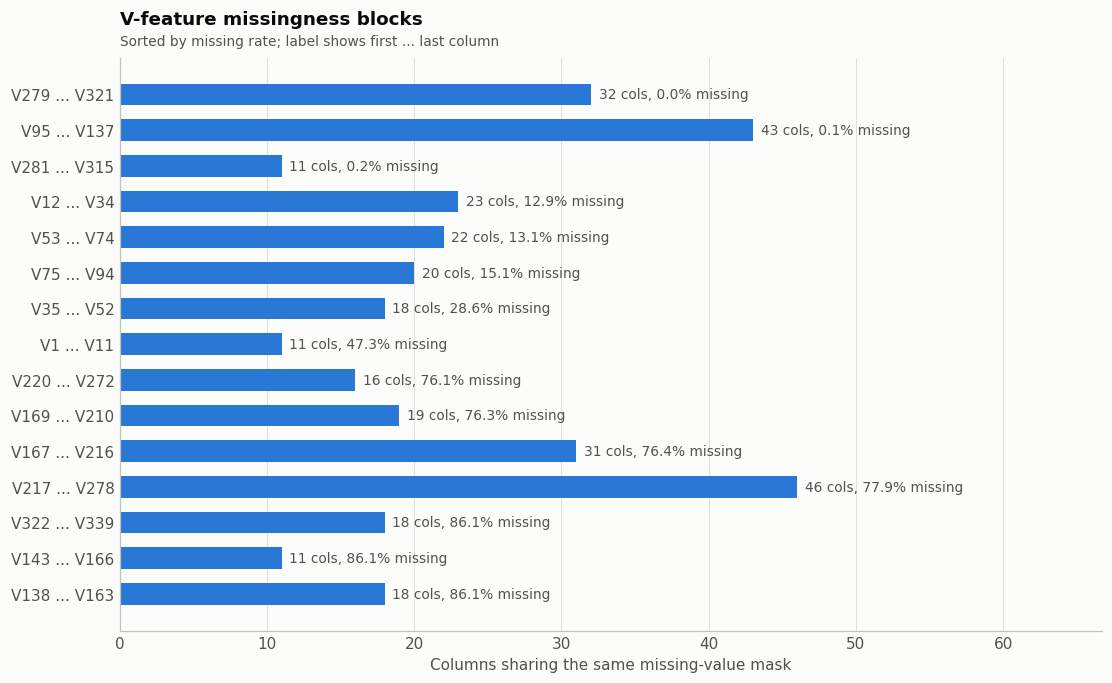

**Finding.** The 339 V-columns have **15 distinct missing-value masks**. 15 masks are shared by two or more columns and together cover 339 columns (100%). An imputer therefore faces whole blocks of absent values at once, and one missing-indicator per block would carry the same information as one per column.

In [14]:
V_COLS = [c for c in df.columns if feature_group(c) == "V"]
masks = {}
for c in V_COLS:
    key = hashlib.sha1(np.packbits(df[c].isna().to_numpy()).tobytes()).hexdigest()
    masks.setdefault(key, []).append(c)
blocks = pd.DataFrame([{"first": cs[0], "last": cs[-1], "n_cols": len(cs), "missing_pct": miss[cs[0]] * 100}
                       for cs in masks.values()]).sort_values(["missing_pct", "n_cols"])
multi = blocks[blocks["n_cols"] >= 2]
SUMMARY["v_missing_blocks"] = {
    "n_v_cols": len(V_COLS), "n_distinct_masks": int(len(blocks)),
    "n_blocks_2plus_cols": int(len(multi)), "cols_in_blocks": int(multi["n_cols"].sum()),
    "blocks": multi.to_dict(orient="records"),
}

fig, ax = plt.subplots(figsize=(10, max(2.5, 0.34 * len(multi) + 1)))
yy = np.arange(len(multi))
ax.barh(yy, multi["n_cols"], height=0.6, color=C["blue"])
for yi, (_, r) in zip(yy, multi.iterrows()):
    ax.annotate(f"{r['n_cols']} cols, {r['missing_pct']:.1f}% missing", xy=(r["n_cols"], yi),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, color=C["ink2"])
ax.set_yticks(yy, [f"{r['first']} ... {r['last']}" if r["n_cols"] > 1 else r["first"]
                   for _, r in multi.iterrows()])
ax.invert_yaxis()
ax.set_xlim(0, multi["n_cols"].max() * 1.45 if len(multi) else 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Columns sharing the same missing-value mask")
titled(ax, "V-feature missingness blocks", "Sorted by missing rate; label shows first ... last column")
finish(fig, "v_missing_blocks.png")

note(f"**Finding.** The {len(V_COLS)} V-columns have **{len(blocks)} distinct missing-value masks**. "
     f"{len(multi)} masks are shared by two or more columns and together cover "
     f"{multi['n_cols'].sum()} columns ({multi['n_cols'].sum() / len(V_COLS):.0%}). "
     f"An imputer therefore faces whole blocks of absent values at once, and one missing-indicator "
     f"per block would carry the same information as one per column.")

## 7. Transaction amount

Amounts are heavily right-skewed, so they are shown on a log scale. The empirical cumulative distribution (ECDF, right) gives the share of transactions at or below each amount. The largest vertical gap between the two ECDF curves is the Kolmogorov–Smirnov statistic D: 0 means identical distributions, 1 means fully separated.

,Non-fraud,Fraud
1st percentile,$9.51,$6.74
5th percentile,$20.73,$13.06
25th percentile,$43.97,$35.04
Median,$68.50,$75.00
75th percentile,$120.00,$161.00
95th percentile,$435.00,$500.00
99th percentile,"$1,104.00",$994.00
Mean,$134.51,$149.24
Max,"$31,937.39","$5,191.00"


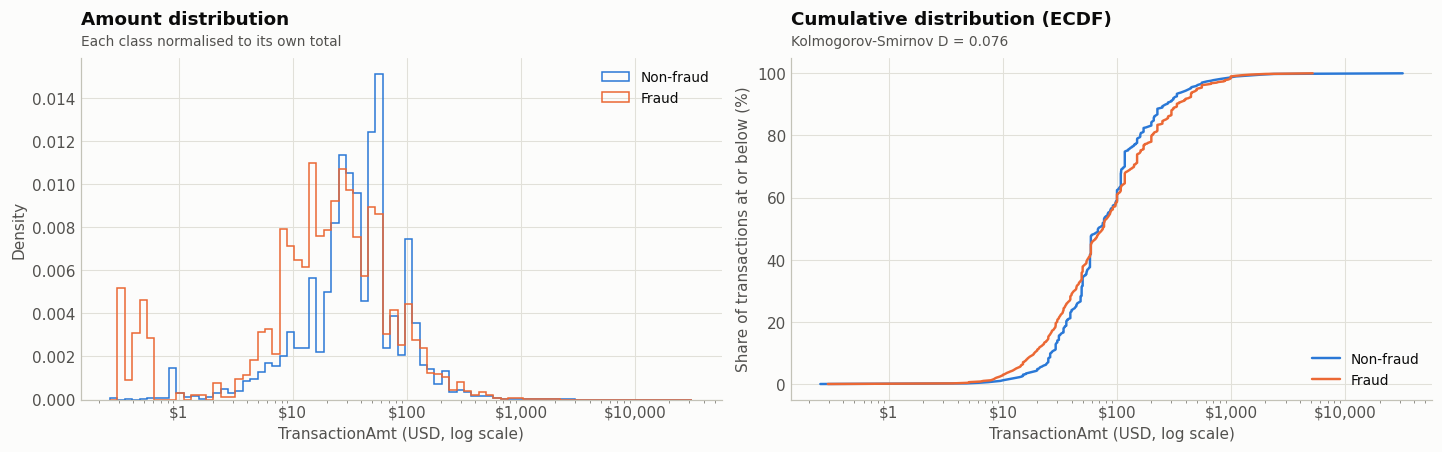

**Finding.** The median fraud amount is **$75.00**, against **$68.50** for non-fraud, so the typical fraud is larger. The largest gap between the two cumulative distributions is KS D = 0.076; the ECDF shows the amount ranges where the classes diverge.

In [15]:
amt = df["TransactionAmt"]
SUMMARY["transaction_amt"] = {
    "median_all": float(amt.median()),
    "median_fraud": float(amt[df[TARGET] == 1].median()),
    "median_nonfraud": float(amt[df[TARGET] == 0].median()),
    "max": float(amt.max()),
}
qs = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
qt = pd.DataFrame({"Non-fraud": amt[y == 0].quantile(qs).to_numpy(),
                   "Fraud": amt[y == 1].quantile(qs).to_numpy()},
                  index=["1st percentile", "5th percentile", "25th percentile", "Median",
                         "75th percentile", "95th percentile", "99th percentile"])
qt.loc["Mean"] = [amt[y == 0].mean(), amt[y == 1].mean()]
qt.loc["Max"] = [amt[y == 0].max(), amt[y == 1].max()]
display(qt.apply(lambda s: s.map(lambda v: f"${v:,.2f}")))

a0, a1 = amt[y == 0].to_numpy(), amt[y == 1].to_numpy()
ks = ks_2samp(a0, a1).statistic
SUMMARY["transaction_amt"]["ks_statistic"] = float(ks)

bins = np.logspace(np.log10(max(amt.min(), 0.1)), np.log10(amt.max()), 80)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.hist(a0, bins=bins, density=True, histtype="step", lw=1.6, color=C["blue"], label="Non-fraud")
ax1.hist(a1, bins=bins, density=True, histtype="step", lw=1.6, color=C["orange"], label="Fraud")
ax1.set_xscale("log")
ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:,.0f}" if x >= 1 else f"${x:g}"))
ax1.set_xlabel("TransactionAmt (USD, log scale)")
ax1.set_ylabel("Density")
ax1.legend()
titled(ax1, "Amount distribution", "Each class normalised to its own total")

grid_q = np.linspace(0, 1, 501)
for a, col, lab in [(a0, C["blue"], "Non-fraud"), (a1, C["orange"], "Fraud")]:
    ax2.plot(np.quantile(a, grid_q), grid_q * 100, color=col, label=lab)
ax2.set_xscale("log")
ax2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:,.0f}" if x >= 1 else f"${x:g}"))
ax2.set_xlabel("TransactionAmt (USD, log scale)")
ax2.set_ylabel("Share of transactions at or below (%)")
ax2.legend(loc="lower right")
titled(ax2, "Cumulative distribution (ECDF)", f"Kolmogorov-Smirnov D = {ks:.3f}")
finish(fig, "transaction_amt.png")

mf, mn = SUMMARY["transaction_amt"]["median_fraud"], SUMMARY["transaction_amt"]["median_nonfraud"]
note(f"**Finding.** The median fraud amount is **${mf:,.2f}**, against **${mn:,.2f}** for non-fraud, so the "
     f"typical fraud is {'larger' if mf > mn else 'smaller' if mf < mn else 'the same size'}. "
     f"The largest gap between the two cumulative distributions is KS D = {ks:.3f}; the ECDF shows "
     f"the amount ranges where the classes diverge.")

### Fraud rate by amount decile

Each point covers one tenth of all transactions, ordered by amount.

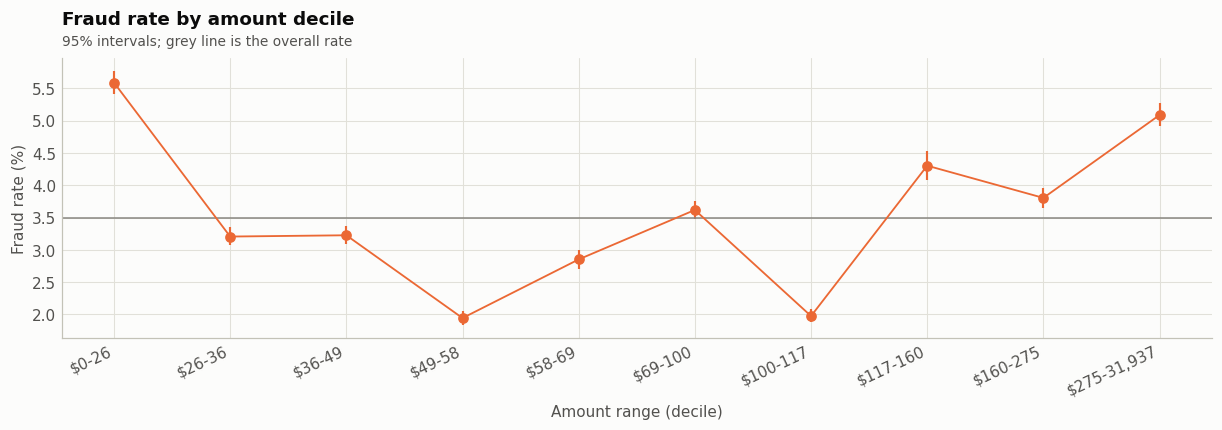

**Finding.** The highest fraud rate is in the **$0-26** decile (5.59%); the lowest is in the $49-58 decile (1.94%).

In [16]:
codes, edges = pd.qcut(amt, 10, labels=False, retbins=True, duplicates="drop")
dec = rate_table(pd.Series(codes, index=df.index))
dec_lab = [f"${edges[i]:,.0f}-{edges[i + 1]:,.0f}" for i in dec.index.astype(int)]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.errorbar(range(len(dec)), dec["rate"] * 100, yerr=rate_err(dec), fmt="o-", color=C["orange"],
            ms=6, lw=1.2, elinewidth=1.4, capsize=0)
ax.axhline(prev * 100, color=C["muted"], lw=1)
ax.set_xticks(range(len(dec)), dec_lab, rotation=25, ha="right")
ax.set_ylabel("Fraud rate (%)")
ax.set_xlabel("Amount range (decile)")
titled(ax, "Fraud rate by amount decile", "95% intervals; grey line is the overall rate")
finish(fig, "fraud_rate_by_amount_decile.png")

SUMMARY["amount_decile_fraud_rate"] = [{"range": l, "rows": int(r["n"]), "fraud_rate": float(r["rate"])}
                                       for l, (_, r) in zip(dec_lab, dec.iterrows())]
hi_i, lo_i = int(np.argmax(dec["rate"].to_numpy())), int(np.argmin(dec["rate"].to_numpy()))
note(f"**Finding.** The highest fraud rate is in the **{dec_lab[hi_i]}** decile ({dec['rate'].iloc[hi_i]:.2%}); "
     f"the lowest is in the {dec_lab[lo_i]} decile ({dec['rate'].iloc[lo_i]:.2%}).")

## 8. Categorical features

Cardinality (the number of distinct values) drives the encoding choice. One-hot encoding adds one column per value, which is impractical for high-cardinality columns, so the pipeline uses ordinal encoding with a reserved code for categories first seen in production.

Highest-cardinality categorical columns:
DeviceInfo       1786
id_33             260
id_31             130
id_30              75
R_emaildomain      60
P_emaildomain      59
ProductCD           5
card6               4
card4               4
id_34               4
dtype: int64


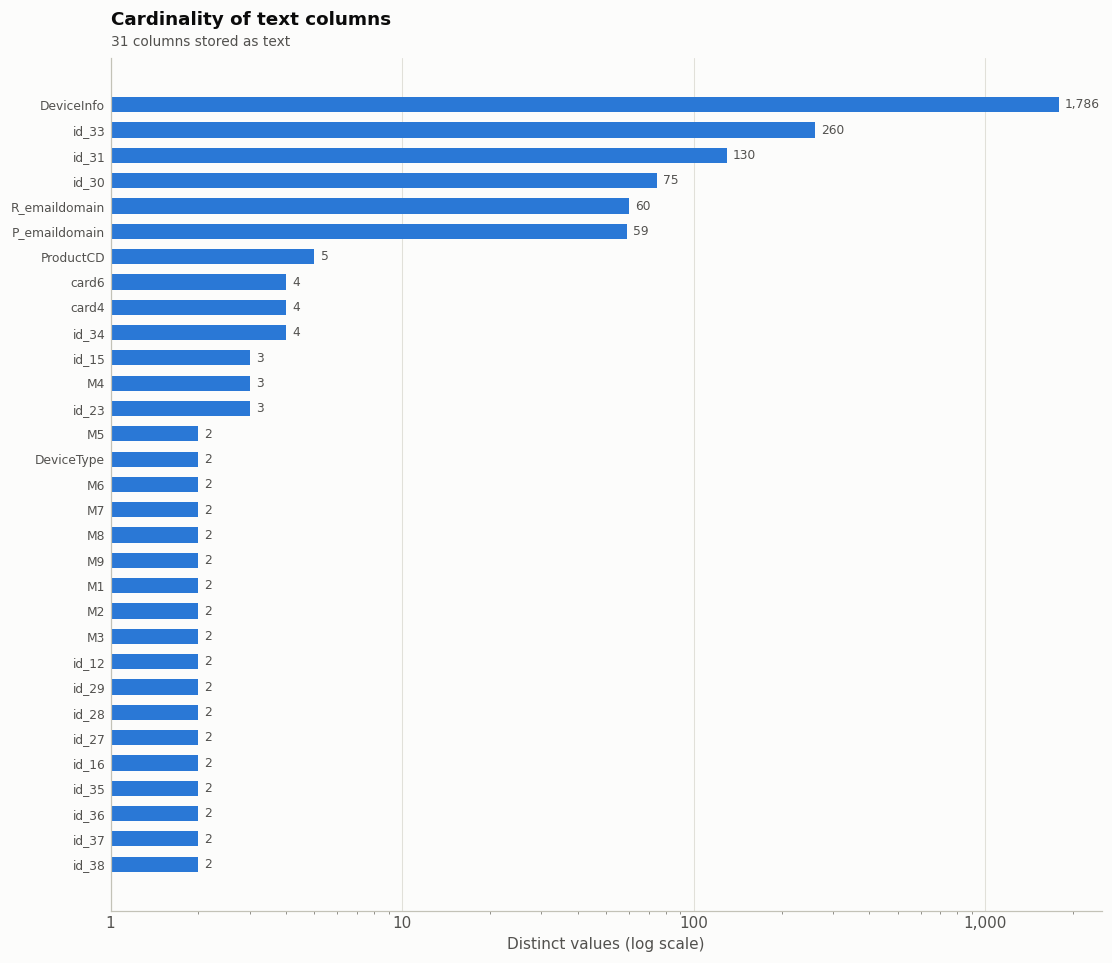

In [17]:
card = {c: int(df[c].nunique(dropna=True)) for c in CAT_COLS}
card_s = pd.Series(card).sort_values(ascending=False)
SUMMARY["categorical_cardinality_top"] = card_s.head(10).to_dict()
print("Highest-cardinality categorical columns:")
print(card_s.head(10))

fig, ax = plt.subplots(figsize=(10, 0.24 * len(card_s) + 1.2))
yy = np.arange(len(card_s))
ax.barh(yy, card_s.clip(lower=1), height=0.6, color=C["blue"])
for yi, v in zip(yy, card_s):
    ax.annotate(f"{v:,}", xy=(max(v, 1), yi), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=C["ink2"])
ax.set_xscale("log")
ax.set_xlim(left=1)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_yticks(yy, card_s.index, fontsize=8)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Distinct values (log scale)")
titled(ax, "Cardinality of text columns", f"{len(card_s)} columns stored as text")
finish(fig, "categorical_cardinality.png")

### Fraud rate by category

Only categories with at least 500 rows are shown (missing values count as their own category). Bars are 95% Wilson intervals and `n` is the row count. A high rate with a wide interval is weaker evidence than a moderate rate with a narrow one.

ProductCD       highest-risk category (>=500 rows): C (11.69%, n=68,519)
card4           highest-risk category (>=500 rows): discover (7.73%, n=6,651)
card6           highest-risk category (>=500 rows): credit (6.68%, n=148,986)
DeviceType      highest-risk category (>=500 rows): mobile (10.17%, n=55,645)


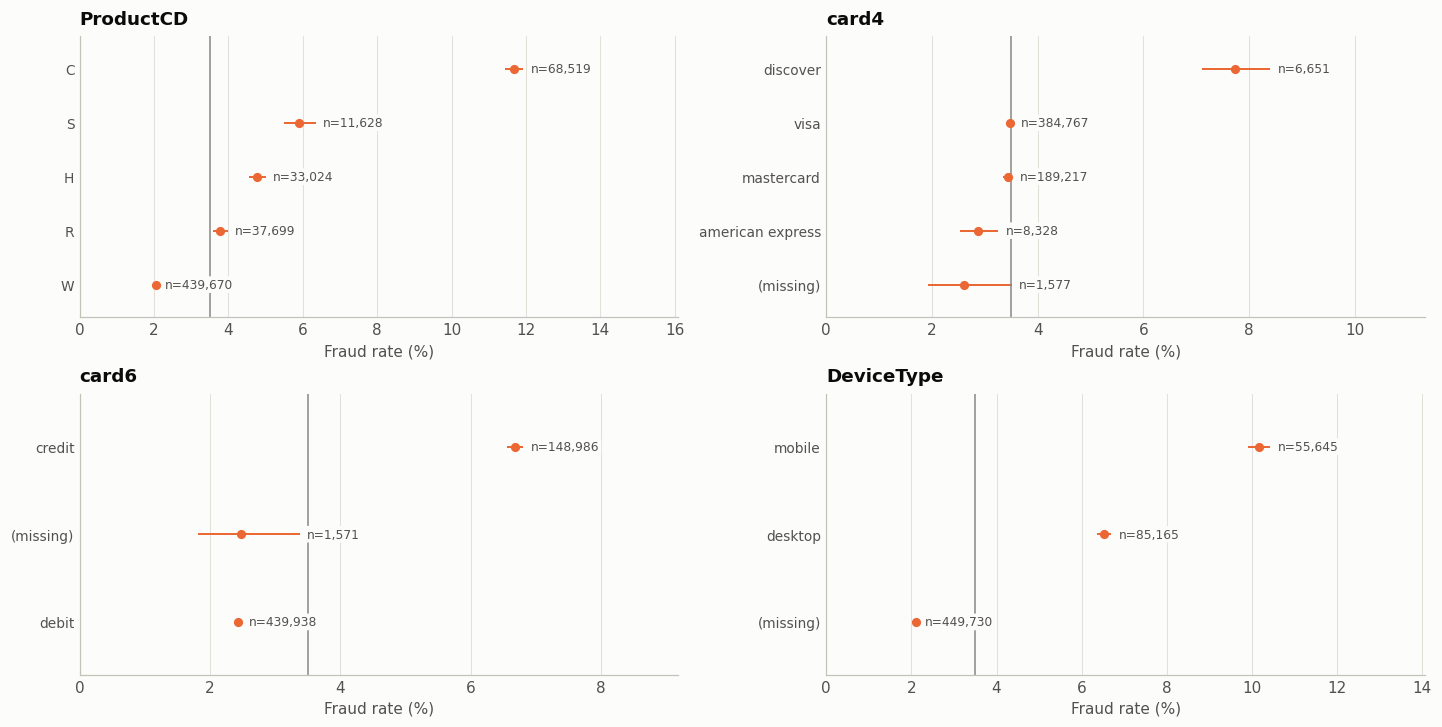

In [18]:
def plot_rates(ax, g, title, sub=None, max_rows=None):
    g = g.sort_values("rate", ascending=False)
    if max_rows:
        g = g.head(max_rows)
    yy = np.arange(len(g))
    ax.errorbar(g["rate"] * 100, yy, xerr=rate_err(g), fmt="o", color=C["orange"], ms=5,
                elinewidth=1.3, capsize=0)
    for yi, (_, r) in zip(yy, g.iterrows()):
        ax.annotate(f"n={int(r['n']):,}", xy=(r["hi"] * 100, yi), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=8, color=C["ink2"],
                    bbox=dict(boxstyle="round,pad=0.15", fc=C["surface"], ec="none"))
    ax.set_yticks(yy, [str(i) for i in g.index], fontsize=9)
    ax.set_ylim(len(g) - 0.4, -0.6)
    ax.set_xlim(0, g["hi"].max() * 100 * 1.35)
    ax.axvline(prev * 100, color=C["muted"], lw=1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Fraud rate (%)")
    titled(ax, title, sub)


RISK = {}


def record_top(col, g):
    """Highest-risk category among those with >= 500 rows (same rule as the earlier version)."""
    if len(g):
        top1 = g["rate"].idxmax()
        RISK[col] = {"category": str(top1), "fraud_rate": float(g.loc[top1, "rate"]),
                     "rows": int(g.loc[top1, "n"])}
        print(f"{col:15s} highest-risk category (>=500 rows): {top1} ({g.loc[top1, 'rate']:.2%}, "
              f"n={g.loc[top1, 'n']:,})")
    else:
        print(f"{col}: n/a")


low_card = [c for c in ["ProductCD", "card4", "card6", "DeviceType"] if c in df.columns]
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5))
for ax, col in zip(axes.flat, low_card):
    g = rate_table(col, min_count=500)
    record_top(col, g)
    plot_rates(ax, g, col)
for ax in axes.flat[len(low_card):]:
    ax.set_visible(False)
finish(fig, "fraud_rate_low_cardinality.png")

P_emaildomain   highest-risk category (>=500 rows): mail.com (18.96%, n=559)
R_emaildomain   highest-risk category (>=500 rows): outlook.com (16.51%, n=2,507)


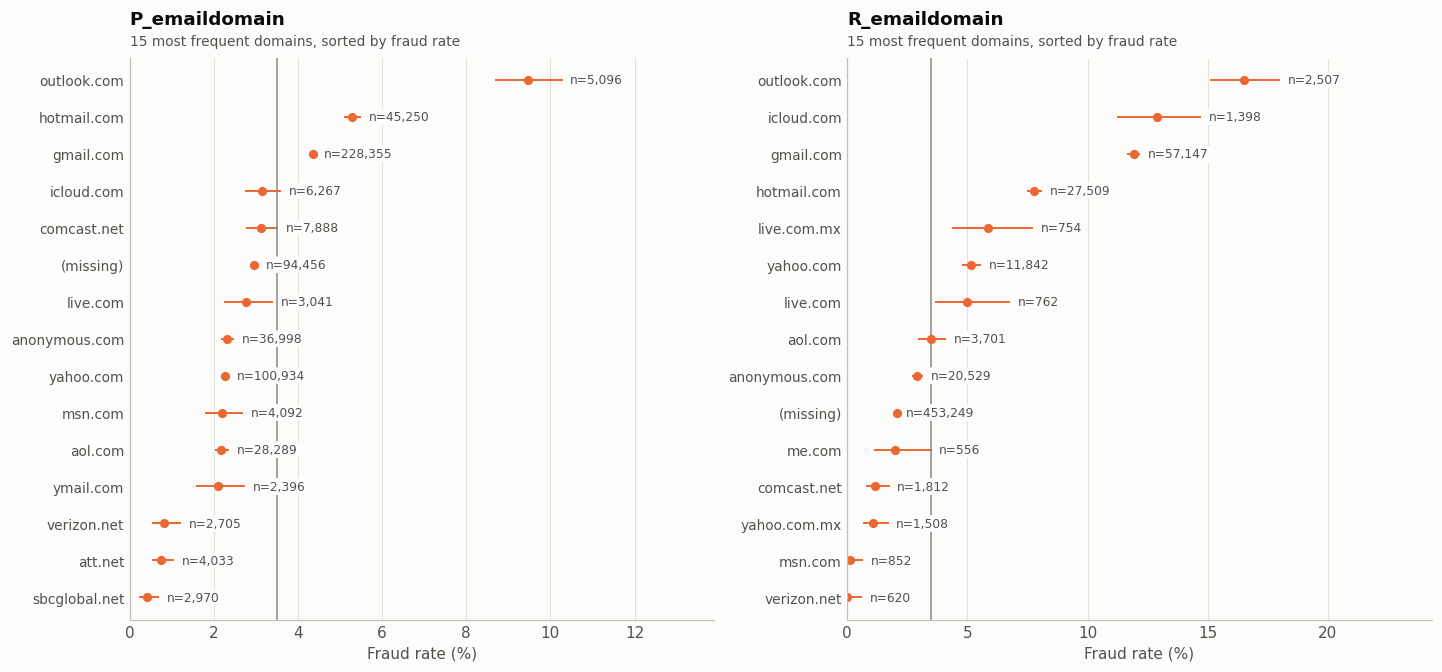

In [19]:
email_cols = [c for c in ["P_emaildomain", "R_emaildomain"] if c in df.columns]
fig, axes = plt.subplots(1, len(email_cols), figsize=(13, 6))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, email_cols):
    g = rate_table(col, min_count=500)
    record_top(col, g)
    g_top = g.sort_values("n", ascending=False).head(15)
    plot_rates(ax, g_top, col, "15 most frequent domains, sorted by fraud rate")
finish(fig, "fraud_rate_email_domains.png")
SUMMARY["highest_risk_category"] = RISK

### Match flags (M1–M9)

Fraud rate for each value of each match flag, missing included. Blank cells mean the value does not occur for that flag.

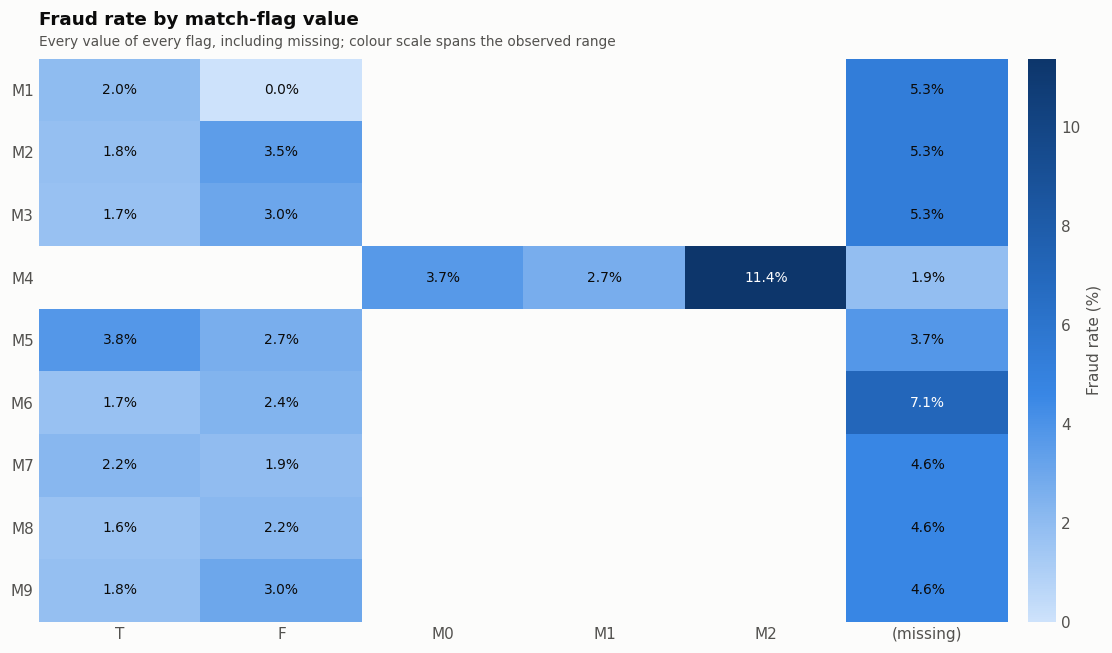

**Finding.** The highest rate is `M4` = `M2` at **11.37%** (n=59,865). For 7 of 9 flags, the missing value has a higher fraud rate than any observed value: M1, M2, M3, M6, M7, M8, M9.

In [20]:
M_COLS = [c for c in df.columns if feature_group(c) == "M"]
mt = {c: rate_table(c) for c in M_COLS}
pref = ["T", "F", "M0", "M1", "M2", "(missing)"]
seen = list(dict.fromkeys(v for c in M_COLS for v in mt[c].index.astype(str)))
values = [v for v in pref if v in seen] + [v for v in seen if v not in pref]
R = pd.DataFrame({c: mt[c]["rate"].rename(index=str) for c in M_COLS}).T.reindex(columns=values) * 100
N = pd.DataFrame({c: mt[c]["n"].rename(index=str) for c in M_COLS}).T.reindex(columns=values)

fig, ax = plt.subplots(figsize=(1.25 * len(values) + 2.5, 0.48 * len(M_COLS) + 1.5))
vmin, vmax = np.nanmin(R.to_numpy()), np.nanmax(R.to_numpy())
vmax = vmax if vmax > vmin else vmin + 1e-9
im = ax.imshow(np.ma.masked_invalid(R.to_numpy()), cmap=SEQ, vmin=vmin, vmax=vmax, aspect="auto")
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        v = R.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9,
                    color="#ffffff" if (v - vmin) / (vmax - vmin) > 0.55 else C["ink"])
ax.set_xticks(range(len(values)), values)
ax.set_yticks(range(len(M_COLS)), M_COLS)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("Fraud rate (%)")
cb.outline.set_visible(False)
titled(ax, "Fraud rate by match-flag value", "Every value of every flag, including missing; colour scale spans the observed range")
finish(fig, "fraud_rate_match_flags.png")

i_max = np.unravel_index(np.nanargmax(R.to_numpy()), R.shape)
miss_higher = [c for c in M_COLS if "(missing)" in R.columns and not np.isnan(R.loc[c, "(missing)"])
               and R.loc[c, "(missing)"] > R.loc[c].drop("(missing)").max()]
SUMMARY["match_flag_fraud_rate_pct"] = {c: {k: float(v) for k, v in R.loc[c].dropna().items()} for c in M_COLS}
note(f"**Finding.** The highest rate is `{R.index[i_max[0]]}` = `{R.columns[i_max[1]]}` "
     f"at **{R.iat[i_max]:.2f}%** (n={int(N.iat[i_max]):,}). For {len(miss_higher)} of {len(M_COLS)} flags, "
     f"the missing value has a higher fraud rate than any observed value"
     + (f": {', '.join(miss_higher)}." if miss_higher else "."))

## 9. Single-feature signal

For each numeric feature, ROC-AUC is computed using that feature alone as the score, on the rows where it is present. AUC 0.5 means no separation. Values further from 0.5 in either direction mean stronger separation; below 0.5 means fraud tends to have *lower* values. Strength is reported as max(AUC, 1 − AUC), and coverage is the share of rows where the feature is present.

Left out: `TransactionDT` (its AUC would measure drift, covered in Section 3) and number-coded categories such as `card1` and `addr1`, whose numeric order has no meaning.

This is a screening view. Features that are weak alone can still matter in combination with others; final feature selection happens in the training notebook (SHAP).

Scored 382 of 382 candidate features (18 number-coded categories left out)


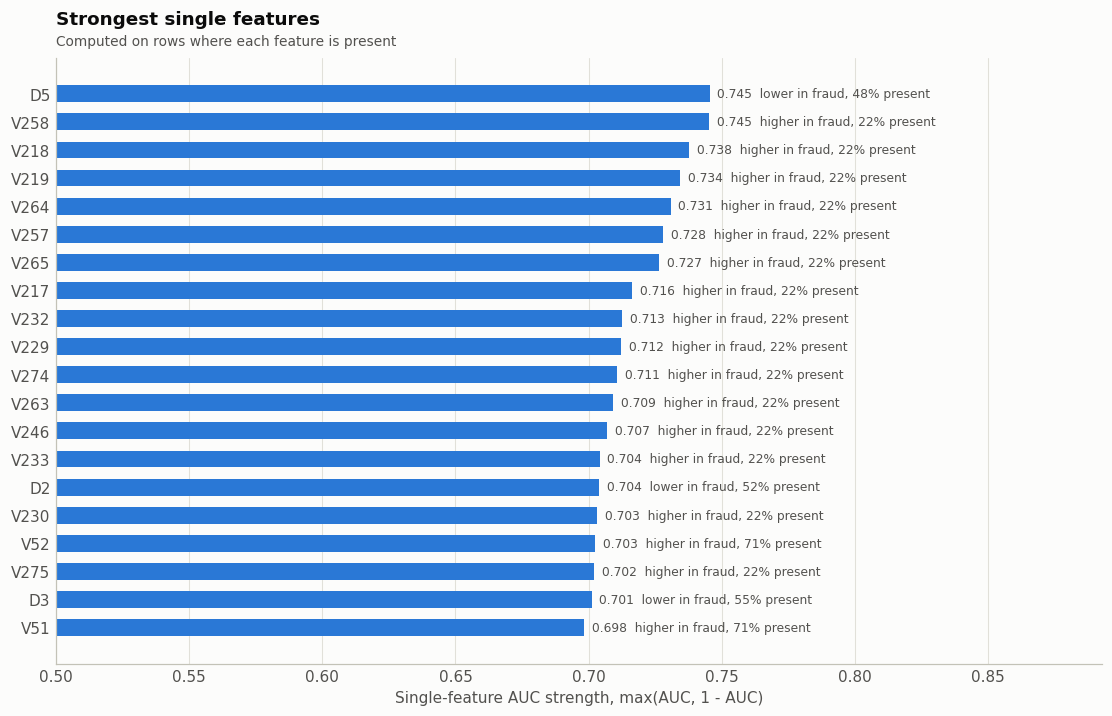

,feature,group,auc,strength,direction,coverage %
0,D5,D,0.2546,0.7454,lower in fraud,47.5
1,V258,V,0.7453,0.7453,higher in fraud,22.1
2,V218,V,0.7377,0.7377,higher in fraud,22.1
3,V219,V,0.7344,0.7344,higher in fraud,22.1
4,V264,V,0.7307,0.7307,higher in fraud,22.1
5,V257,V,0.7279,0.7279,higher in fraud,22.1
6,V265,V,0.7266,0.7266,higher in fraud,22.1
7,V217,V,0.7163,0.7163,higher in fraud,22.1
8,V232,V,0.7126,0.7126,higher in fraud,22.1
9,V229,V,0.7123,0.7123,higher in fraud,22.1


**Finding.** The strongest single feature is **`D5`** (AUC strength 0.745, lower in fraud, present in 48% of rows). 137 features reach a strength of 0.60 or more on their own. Best feature per group: D 0.745, V 0.745, C 0.688, Identity 0.618, Distance 0.543, Amount 0.502.

In [21]:
CODED_CATEGORICAL = [c for c in NUM_COLS
                     if c in ("card1", "card2", "card3", "card5", "addr1", "addr2")
                     or (c.startswith("id_") and c[3:].isdigit() and int(c[3:]) >= 12)]
CONT_COLS = [c for c in NUM_COLS if c not in CODED_CATEGORICAL and c != "TransactionDT"]


def auc_observed(x, y, min_class=50):
    """ROC-AUC of a single feature on rows where it is present (Mann-Whitney form, ties averaged)."""
    ok = ~np.isnan(x)
    yo = y[ok]
    n1 = int(yo.sum())
    n0 = len(yo) - n1
    if n1 < min_class or n0 < min_class:
        return np.nan, ok.mean()
    r = rankdata(x[ok])
    return (r[yo == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0), ok.mean()


rows = []
for c in CONT_COLS:
    auc, cov = auc_observed(df[c].to_numpy(dtype=np.float64), y)
    rows.append({"feature": c, "group": feature_group(c), "auc": auc, "coverage": cov})
uni = pd.DataFrame(rows).dropna(subset=["auc"])
uni["strength"] = np.maximum(uni["auc"], 1 - uni["auc"])
uni["direction"] = np.where(uni["auc"] >= 0.5, "higher in fraud", "lower in fraud")
uni = uni.sort_values("strength", ascending=False).reset_index(drop=True)
print(f"Scored {len(uni)} of {len(CONT_COLS)} candidate features "
      f"({len(CODED_CATEGORICAL)} number-coded categories left out)")

top20 = uni.head(20)
fig, ax = plt.subplots(figsize=(10, 6.4))
yy = np.arange(len(top20))
ax.barh(yy, top20["strength"] - 0.5, left=0.5, height=0.6, color=C["blue"])
for yi, (_, r) in zip(yy, top20.iterrows()):
    ax.annotate(f"{r['strength']:.3f}  {r['direction']}, {r['coverage']:.0%} present",
                xy=(r["strength"], yi), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=8, color=C["ink2"])
ax.set_yticks(yy, top20["feature"])
ax.invert_yaxis()
ax.set_xlim(0.5, 0.5 + (top20["strength"].max() - 0.5) * 1.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Single-feature AUC strength, max(AUC, 1 - AUC)")
titled(ax, "Strongest single features", "Computed on rows where each feature is present")
finish(fig, "univariate_auc_top20.png")

display(top20.assign(coverage=lambda d: (d["coverage"] * 100).round(1),
                     auc=lambda d: d["auc"].round(4), strength=lambda d: d["strength"].round(4))
             [["feature", "group", "auc", "strength", "direction", "coverage"]]
             .rename(columns={"coverage": "coverage %"}))

SUMMARY["univariate_auc_top20"] = top20[["feature", "auc", "coverage"]].to_dict(orient="records")
by_group = uni.groupby("group")["strength"].max().sort_values(ascending=False)
note(f"**Finding.** The strongest single feature is **`{uni.loc[0, 'feature']}`** "
     f"(AUC strength {uni.loc[0, 'strength']:.3f}, {uni.loc[0, 'direction']}, present in "
     f"{uni.loc[0, 'coverage']:.0%} of rows). {int((uni['strength'] >= 0.6).sum())} features reach a strength "
     f"of 0.60 or more on their own. Best feature per group: "
     + ", ".join(f"{g} {v:.3f}" for g, v in by_group.items()) + ".")

### Distributions of the strongest features

Values are clipped to the 1st–99th percentile. Features that are non-negative with a long right tail are shown on a log(1 + x) axis.

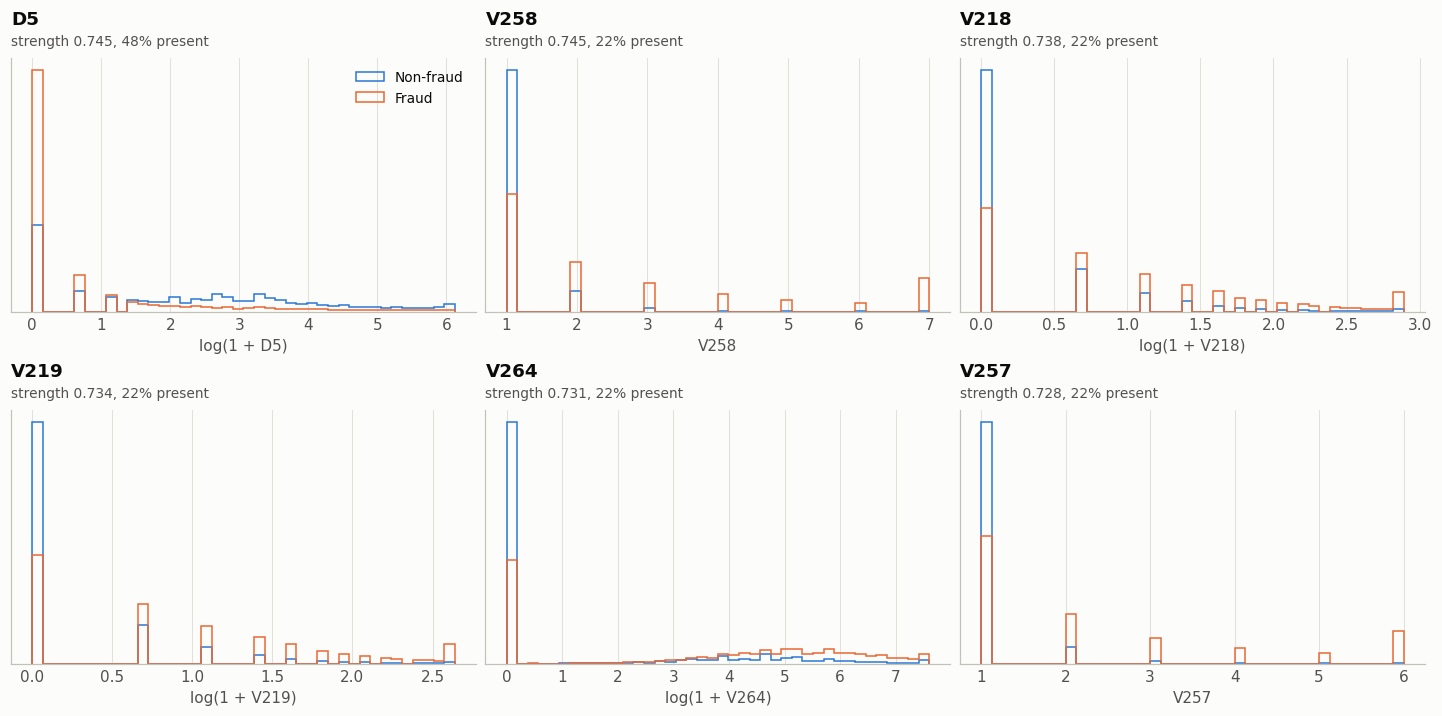

In [22]:
top6 = uni["feature"].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, c in zip(axes.flat, top6):
    x = df[c].to_numpy(dtype=np.float64)
    ok = ~np.isnan(x)
    lo, hi = np.quantile(x[ok], [0.01, 0.99])
    xc = np.clip(x[ok], lo, hi)
    log_axis = lo >= 0 and hi > 10 * (np.median(x[ok]) + 1)
    if log_axis:
        xc = np.log1p(xc)
    yo = y[ok]
    b = np.histogram_bin_edges(xc, bins=40)
    ax.hist(xc[yo == 0], bins=b, density=True, histtype="step", lw=1.6, color=C["blue"], label="Non-fraud")
    ax.hist(xc[yo == 1], bins=b, density=True, histtype="step", lw=1.6, color=C["orange"], label="Fraud")
    ax.set_xlabel(f"log(1 + {c})" if log_axis else c)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    r = uni.set_index("feature").loc[c]
    titled(ax, c, f"strength {r['strength']:.3f}, {r['coverage']:.0%} present")
for ax in axes.flat[len(top6):]:
    ax.set_visible(False)
axes.flat[0].legend(loc="upper right")
finish(fig, "top_feature_distributions.png")

### C-features: Pearson vs. Spearman

C-features are counts with long tails. Pearson correlation measures linear association and is pulled around by extreme values; Spearman correlation uses ranks, so it picks up any consistently increasing or decreasing relationship. Both are computed against the 0/1 target.

C-features most correlated with isFraud (Pearson, as before):
C2     0.037
C8     0.032
C12    0.032
C9    -0.032
C5    -0.031
C1     0.031
C4     0.030
C10    0.028
Name: isFraud, dtype: float64


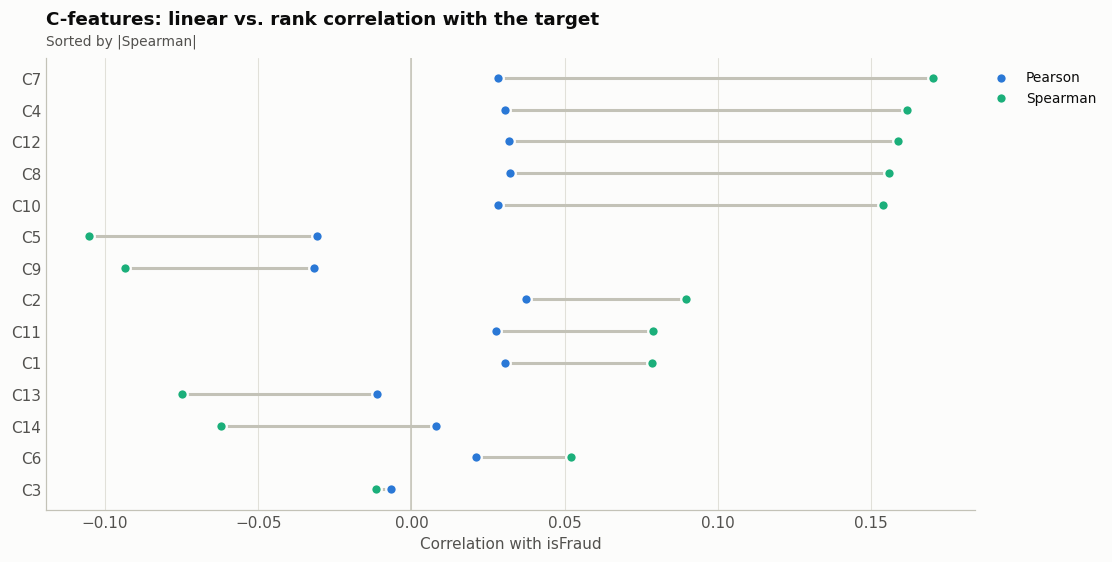

,pearson,spearman,auc
C7,0.0282,0.1702,0.6474
C4,0.0304,0.1618,0.6877
C12,0.0319,0.1588,0.6635
C8,0.0321,0.1560,0.6832
C10,0.0284,0.1538,0.6779
C5,-0.0308,-0.1054,0.3576
C9,-0.0317,-0.0935,0.3600
C2,0.0372,0.0895,0.6289
C11,0.0275,0.0790,0.6045
C1,0.0306,0.0786,0.6131


**Finding.** The largest |Pearson| among C-features is 0.037; the largest |Spearman| is **0.170** (`C7`). Spearman exceeds Pearson in absolute value for 14 of 14 C-features.

In [23]:
C_COLS = [c for c in df.columns if feature_group(c) == "C"]
pear = df[C_COLS + [TARGET]].corr()[TARGET].drop(TARGET)
c_ranks = df[C_COLS].rank()
spear = c_ranks.corrwith(df[TARGET].rank())
cc = (pd.DataFrame({"pearson": pear, "spearman": spear})
        .join(uni.set_index("feature")[["auc"]])
        .sort_values("spearman", key=np.abs, ascending=False))
print("C-features most correlated with isFraud (Pearson, as before):")
print(pear.sort_values(key=np.abs, ascending=False).head(8).round(3))

fig, ax = plt.subplots(figsize=(10, 5))
yy = np.arange(len(cc))
for yi, (_, r) in zip(yy, cc.iterrows()):
    ax.plot([r["pearson"], r["spearman"]], [yi, yi], color=C["axis"], lw=2, zorder=1)
ax.scatter(cc["pearson"], yy, s=48, color=C["blue"], edgecolor=C["surface"], lw=1.5, zorder=2, label="Pearson")
ax.scatter(cc["spearman"], yy, s=48, color=C["aqua"], edgecolor=C["surface"], lw=1.5, zorder=2, label="Spearman")
ax.axvline(0, color=C["axis"], lw=1)
ax.set_yticks(yy, cc.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlation with isFraud")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
titled(ax, "C-features: linear vs. rank correlation with the target", "Sorted by |Spearman|")
finish(fig, "c_features_pearson_vs_spearman.png")

display(cc.round(4))
SUMMARY["c_feature_target_corr"] = {c: {"pearson": float(r["pearson"]), "spearman": float(r["spearman"])}
                                    for c, r in cc.iterrows()}
note(f"**Finding.** The largest |Pearson| among C-features is {pear.abs().max():.3f}; the largest |Spearman| is "
     f"**{spear.abs().max():.3f}** (`{spear.abs().idxmax()}`). Spearman exceeds Pearson in absolute value for "
     f"{int((spear.abs() > pear.abs()).sum())} of {len(C_COLS)} C-features.")

## 10. Redundant features

Highly correlated features carry largely the same information. They slow training, split feature-importance scores between near-copies, and make model explanations harder to read.

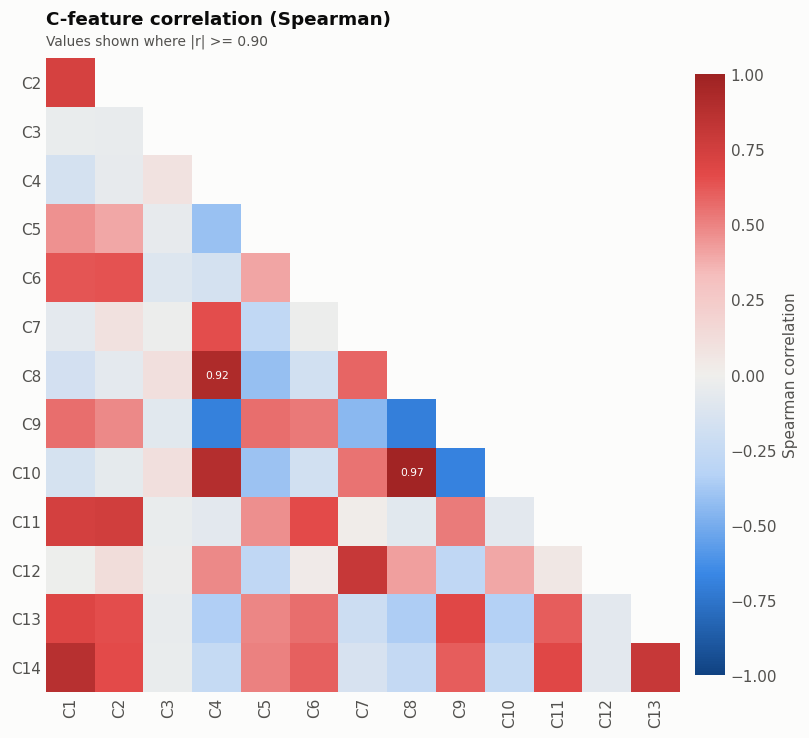

,a,b,spearman
0,C10,C8,0.970
1,C8,C4,0.915
2,C10,C4,0.890
3,C14,C1,0.873
4,C12,C7,0.804
5,C14,C13,0.804
6,C11,C2,0.756
7,C11,C1,0.737
8,C2,C1,0.731
9,C9,C8,-0.701


In [24]:
c_corr = c_ranks.corr()
SUMMARY["c_feature_spearman_pairs_over_0_9"] = int(((c_corr.abs() > 0.9).sum().sum() - len(C_COLS)) // 2)
sub = c_corr.iloc[1:, :-1]  # lower triangle without the diagonal
mask_upper = np.triu(np.ones_like(sub, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.6))
im = ax.imshow(np.ma.masked_array(sub.to_numpy(), mask=mask_upper), cmap=DIV, vmin=-1, vmax=1)
for i in range(sub.shape[0]):
    for j in range(i + 1):
        v = sub.iat[i, j]
        if abs(v) >= 0.9:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="#ffffff")
ax.set_xticks(range(sub.shape[1]), sub.columns, rotation=90)
ax.set_yticks(range(sub.shape[0]), sub.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("Spearman correlation")
cb.outline.set_visible(False)
titled(ax, "C-feature correlation (Spearman)", "Values shown where |r| >= 0.90")
finish(fig, "c_feature_correlation.png")

pairs = (c_corr.where(np.tril(np.ones_like(c_corr, dtype=bool), k=-1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs.reindex(pairs["spearman"].abs().sort_values(ascending=False).index)
display(pairs.head(10).round(3).reset_index(drop=True))

### V-features

Correlations are computed on a random sample of 50,000 rows, using the rows where both columns are present (at least 1,000). The greedy count goes through the columns in order and keeps a column only if its |r| with every column already kept is at most 0.95.

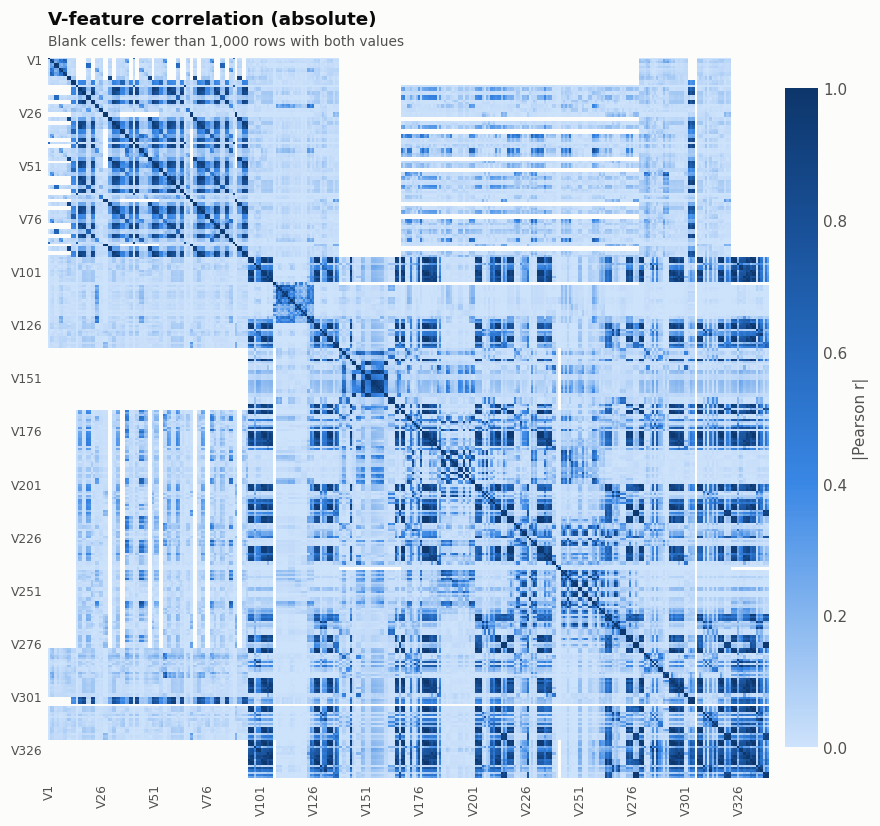

**Finding.** Among 339 V-features, **634 pairs** have |r| > 0.95 (of 48,826 pairs with enough overlap). The greedy filter keeps **226 of 339** columns (67%). The kept list is saved in `eda_summary.json` for comparison with SHAP-based selection.

In [25]:
samp = df[V_COLS].sample(n=min(50_000, len(df)), random_state=SEED)
v_corr = samp.corr(min_periods=1000).abs()
vals = v_corr.to_numpy()
iu = np.triu_indices_from(vals, k=1)
upper = vals[iu]
n_pairs_95 = int(np.nansum(upper > 0.95))

kept = []
for i, c in enumerate(V_COLS):
    if not kept or not np.any(np.nan_to_num(vals[i, kept]) > 0.95):
        kept.append(i)
SUMMARY["v_high_corr_pairs_over_0_95"] = n_pairs_95
SUMMARY["v_greedy_kept_at_0_95"] = len(kept)
SUMMARY["v_greedy_kept_columns"] = [V_COLS[i] for i in kept]

fig, ax = plt.subplots(figsize=(8.5, 7.4))
im = ax.imshow(np.ma.masked_invalid(vals), cmap=SEQ, vmin=0, vmax=1, interpolation="nearest")
tick_idx = list(range(0, len(V_COLS), 25))
ax.set_xticks(tick_idx, [V_COLS[i] for i in tick_idx], rotation=90, fontsize=8)
ax.set_yticks(tick_idx, [V_COLS[i] for i in tick_idx], fontsize=8)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("|Pearson r|")
cb.outline.set_visible(False)
titled(ax, "V-feature correlation (absolute)", "Blank cells: fewer than 1,000 rows with both values")
finish(fig, "v_feature_correlation.png")

note(f"**Finding.** Among {len(V_COLS)} V-features, **{n_pairs_95:,} pairs** have |r| > 0.95 "
     f"(of {int(np.sum(~np.isnan(upper))):,} pairs with enough overlap). The greedy filter keeps "
     f"**{len(kept)} of {len(V_COLS)}** columns ({len(kept) / len(V_COLS):.0%}). "
     f"The kept list is saved in `eda_summary.json` for comparison with SHAP-based selection.")

## 11. Distribution shift between core train and holdout (PSI)

The Population Stability Index compares a feature's distribution in two periods:

$$\text{PSI} = \sum_i (a_i - e_i)\,\ln\frac{a_i}{e_i}$$

where $e_i$ is the share of core-train rows in bin $i$ and $a_i$ the share of holdout rows. Numeric features are cut into 10 bins at core-train deciles plus one bin for missing values; text features use one bin per category. Empty bins are floored at 0.0001 to keep the logarithm finite.

A common rule of thumb (Lewis, 1994) reads below 0.10 as little change, 0.10–0.25 as moderate change and above 0.25 as significant change. The cut-offs do not adjust for sample size or number of bins, so they are used here for screening, not as a statistical test (see this [review of population stability testing](https://arxiv.org/abs/2303.01227)).

Features that are both strong (Section 9) and unstable deserve the most attention: the model may learn a pattern that is changing.

Features per PSI band: {'< 0.10': 406, '0.10-0.25': 5, '>= 0.25': 20}


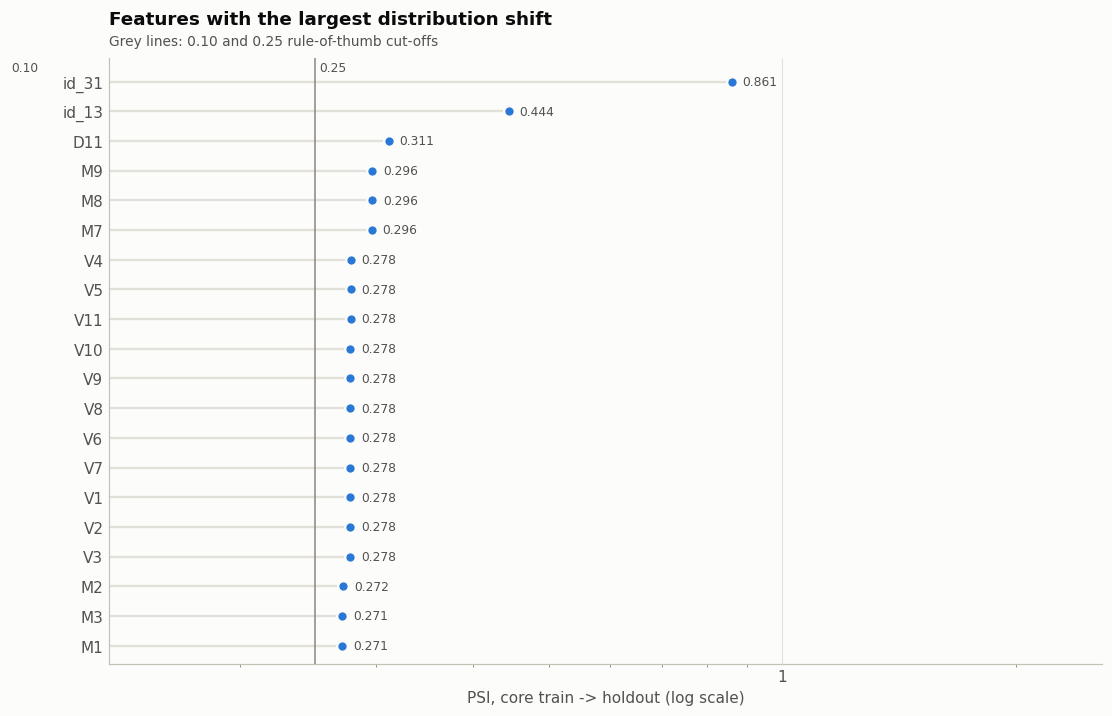

In [26]:
core = df.iloc[:i_val]
hold = df.iloc[i_hold:]
EPS = 1e-4


def psi_numeric(e, a, n_bins=10):
    eo = e[~np.isnan(e)]
    edges = np.unique(np.quantile(eo, np.linspace(0, 1, n_bins + 1)[1:-1])) if len(eo) else np.array([])

    def dist(x):
        codes = np.where(np.isnan(x), len(edges) + 1, np.searchsorted(edges, x, side="right"))
        return np.bincount(codes, minlength=len(edges) + 2) / len(x)

    p, q = np.clip(dist(e), EPS, None), np.clip(dist(a), EPS, None)
    return float(np.sum((q - p) * np.log(q / p)))


def psi_categorical(e, a):
    e = e.astype("object").where(e.notna(), "(missing)")
    a = a.astype("object").where(a.notna(), "(missing)")
    p, q = e.value_counts(normalize=True), a.value_counts(normalize=True)
    idx = p.index.union(q.index)
    p = p.reindex(idx, fill_value=0).clip(lower=EPS)
    q = q.reindex(idx, fill_value=0).clip(lower=EPS)
    return float(((q - p) * np.log(q / p)).sum())


rows = []
for c in NUM_COLS:
    if c == "TransactionDT":
        continue
    rows.append({"feature": c, "group": feature_group(c), "kind": "numeric",
                 "psi": psi_numeric(core[c].to_numpy(dtype=np.float64), hold[c].to_numpy(dtype=np.float64))})
for c in CAT_COLS:
    rows.append({"feature": c, "group": feature_group(c), "kind": "text",
                 "psi": psi_categorical(core[c], hold[c])})
psi = pd.DataFrame(rows).sort_values("psi", ascending=False).reset_index(drop=True)
psi["band"] = pd.cut(psi["psi"], [-np.inf, 0.10, 0.25, np.inf], right=False,
                     labels=["< 0.10", "0.10-0.25", ">= 0.25"])
bands = psi["band"].value_counts().reindex(["< 0.10", "0.10-0.25", ">= 0.25"])
print("Features per PSI band:", bands.to_dict())

top_psi = psi.head(20)
fig, ax = plt.subplots(figsize=(10, 6.4))
yy = np.arange(len(top_psi))
xv = top_psi["psi"].clip(lower=EPS)
ax.hlines(yy, EPS, xv, color=C["grid"], lw=1.5, zorder=1)
ax.scatter(xv, yy, s=48, color=C["blue"], edgecolor=C["surface"], lw=1.5, zorder=2)
for yi, v in zip(yy, top_psi["psi"]):
    ax.annotate(f"{v:.3g}", xy=(max(v, EPS), yi), xytext=(7, 0), textcoords="offset points",
                va="center", fontsize=8, color=C["ink2"])
for t in (0.10, 0.25):
    ax.axvline(t, color=C["muted"], lw=1)
    ax.annotate(f"{t:.2f}", xy=(t, 1), xycoords=("data", "axes fraction"), xytext=(3, -2),
                textcoords="offset points", va="top", fontsize=8, color=C["ink2"])
ax.set_xscale("log")
ax.set_xlim(max(EPS, xv.min() * 0.5), max(1.0, xv.max() * 3))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_yticks(yy, top_psi["feature"])
ax.set_ylim(len(top_psi) - 0.4, -0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("PSI, core train -> holdout (log scale)")
titled(ax, "Features with the largest distribution shift", "Grey lines: 0.10 and 0.25 rule-of-thumb cut-offs")
finish(fig, "psi_top20.png")

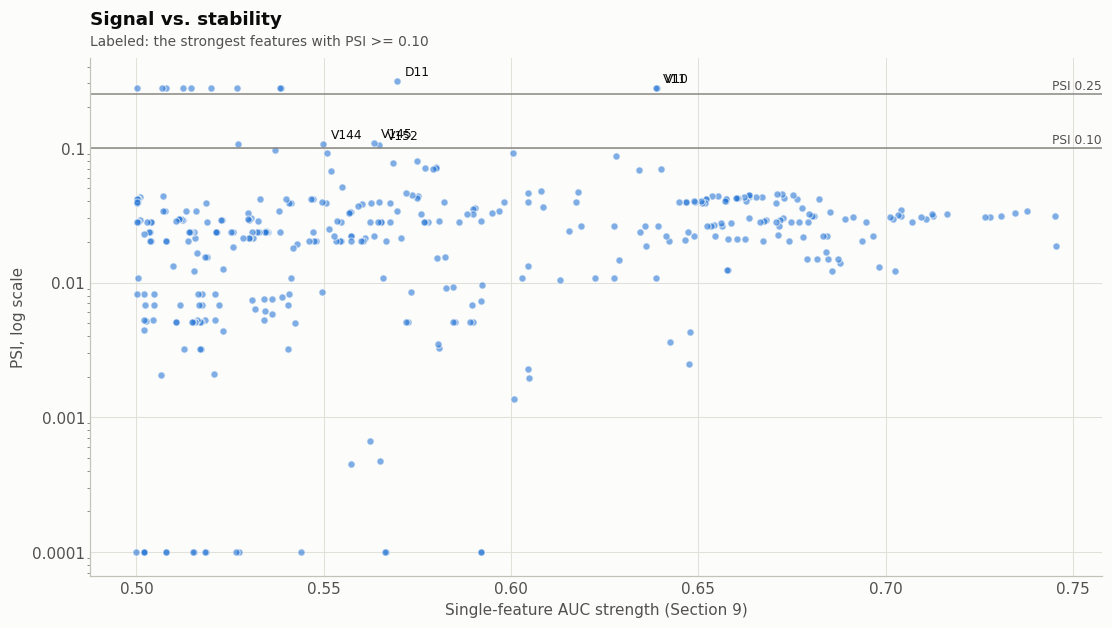

**Finding.** PSI by band across 431 features: below 0.10: 406; 0.10-0.25: 5; **0.25 or above: 20**. The largest shift is `id_31` (PSI 0.86). Groups most represented at 0.25 or above: V (11), M (6), Identity (2), D (1). Strong features that also shift (PSI >= 0.10): `V10`, `V11`, `D11`, `V152`, `V145`, `V144`.

In [27]:
sv = uni.merge(psi[["feature", "psi"]], on="feature", how="left")
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.scatter(sv["strength"], sv["psi"].clip(lower=EPS), s=22, color=C["blue"], alpha=0.6,
           edgecolor=C["surface"], lw=0.8)
for t in (0.10, 0.25):
    ax.axhline(t, color=C["muted"], lw=1)
    ax.annotate(f"PSI {t:.2f}", xy=(1, t), xycoords=("axes fraction", "data"), xytext=(0, 3),
                textcoords="offset points", ha="right", fontsize=8, color=C["ink2"])
watch = sv[sv["psi"] >= 0.10].sort_values("strength", ascending=False).head(6)
for _, r in watch.iterrows():
    ax.annotate(r["feature"], xy=(r["strength"], r["psi"]), xytext=(5, 4), textcoords="offset points",
                fontsize=8, color=C["ink"])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Single-feature AUC strength (Section 9)")
ax.set_ylabel("PSI, log scale")
titled(ax, "Signal vs. stability", "Labeled: the strongest features with PSI >= 0.10")
finish(fig, "signal_vs_stability.png")

high = psi[psi["psi"] >= 0.25]
SUMMARY["psi_bands"] = {k: int(v) for k, v in bands.items()}
SUMMARY["psi_top20"] = top_psi[["feature", "psi"]].to_dict(orient="records")
SUMMARY["strong_and_shifting"] = watch[["feature", "strength", "psi"]].to_dict(orient="records")
grp_high = high["group"].value_counts()
note(f"**Finding.** PSI by band across {len(psi)} features: below 0.10: {bands['< 0.10']}; "
     f"0.10-0.25: {bands['0.10-0.25']}; **0.25 or above: {bands['>= 0.25']}**. The largest shift is "
     f"`{psi.loc[0, 'feature']}` (PSI {psi.loc[0, 'psi']:.2f}). "
     + (f"Groups most represented at 0.25 or above: "
        + ", ".join(f"{g} ({n})" for g, n in grp_high.head(4).items()) + ". " if len(high) else "")
     + (f"Strong features that also shift (PSI >= 0.10): {', '.join(f'`{f}`' for f in watch['feature'])}."
        if len(watch) else "No feature in the scored set has PSI >= 0.10."))

## 12. Summary and handoff to training

In [28]:
wkf = SUMMARY["weekly_fraud_rate"]
vb = SUMMARY["v_missing_blocks"]
KEY_FINDINGS = [
    f"Fraud prevalence {prev:.2%} -> severe imbalance: class weights + PR-AUC "
    f"(accuracy is uninformative).",
    f"Daily fraud rate drifts between "
    f"{SUMMARY['daily_fraud_rate']['min_pct']:.2f}% and "
    f"{SUMMARY['daily_fraud_rate']['max_pct']:.2f}% -> time-based split is required.",
    f"Unlabeled test files start after the labeled data ends "
    f"(strictly_after={SUMMARY['test_after_train']}) -> valid as Phase 2 replay "
    f"traffic, never for evaluation.",
    f"Identity coverage {identity_coverage:.1%}; "
    f"{SUMMARY['missingness']['cols_over_90pct_missing']} columns are >90% missing "
    f"-> imputation must be fitted on training data only and tolerate absent blocks.",
    f"Categorical cardinality up to "
    f"{int(card_s.iloc[0])} ({card_s.index[0]}) -> ordinal encoding with reserved "
    f"unseen-category code, not one-hot.",
    # Added in this version
    f"{wkf['weeks_interval_excludes_overall']} of {wkf['n_weeks']} weeks have a 95% interval that excludes "
    f"the overall fraud rate (about 5% expected if the rate were constant).",
    f"Longest gap inside the training period: {SUMMARY['max_gap_within_train_hours']:.1f} hours; "
    f"test starts {SUMMARY['train_test_gap_days']:.1f} days after training ends.",
    f"Fraud rate with an identity record {r_id:.2%} vs. {r_no:.2%} without; "
    f"{SUMMARY['n_cols_missing_gap_over_1pp']} columns show a missing-vs-present gap above 1 percentage point.",
    f"V-features have {vb['n_distinct_masks']} distinct missing-value masks; {vb['n_blocks_2plus_cols']} shared "
    f"masks cover {vb['cols_in_blocks']} of {vb['n_v_cols']} columns.",
    f"Median amount: fraud ${mf:,.2f} vs. non-fraud ${mn:,.2f}; KS D = {ks:.3f}.",
    f"Strongest single feature: {uni.loc[0, 'feature']} (AUC strength {uni.loc[0, 'strength']:.3f}).",
    f"{n_pairs_95:,} V-feature pairs have |r| > 0.95; a greedy filter keeps {len(kept)} of {len(V_COLS)}.",
    f"{bands['>= 0.25']} features have PSI >= 0.25 between core train and holdout; "
    f"largest: {psi.loc[0, 'feature']} ({psi.loc[0, 'psi']:.2f}).",
]
SUMMARY["key_findings"] = KEY_FINDINGS
note("\n".join(f"{i}. {k}" for i, k in enumerate(KEY_FINDINGS, 1)))

with open(SUMMARY_PATH, "w") as f:
    json.dump(SUMMARY, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print(f"\nWrote {SUMMARY_PATH}")
print(f"Figures in {FIG_DIR}:")
for name in sorted(os.listdir(FIG_DIR)):
    print("  -", name)
print("Next: run training/kaggle_train.py (same DATA_DIR auto-detection).")

1. Fraud prevalence 3.50% -> severe imbalance: class weights + PR-AUC (accuracy is uninformative).
2. Daily fraud rate drifts between 1.10% and 6.99% -> time-based split is required.
3. Unlabeled test files start after the labeled data ends (strictly_after=True) -> valid as Phase 2 replay traffic, never for evaluation.
4. Identity coverage 24.4%; 12 columns are >90% missing -> imputation must be fitted on training data only and tolerate absent blocks.
5. Categorical cardinality up to 1786 (DeviceInfo) -> ordinal encoding with reserved unseen-category code, not one-hot.
6. 18 of 27 weeks have a 95% interval that excludes the overall fraud rate (about 5% expected if the rate were constant).
7. Longest gap inside the training period: 1.1 hours; test starts 30.0 days after training ends.
8. Fraud rate with an identity record 7.85% vs. 2.09% without; 304 columns show a missing-vs-present gap above 1 percentage point.
9. V-features have 15 distinct missing-value masks; 15 shared masks cover 339 of 339 columns.
10. Median amount: fraud $75.00 vs. non-fraud $68.50; KS D = 0.076.
11. Strongest single feature: D5 (AUC strength 0.745).
12. 634 V-feature pairs have |r| > 0.95; a greedy filter keeps 226 of 339.
13. 20 features have PSI >= 0.25 between core train and holdout; largest: id_31 (0.86).


Wrote /kaggle/working/eda_summary.json
Figures in /kaggle/working/eda_figures:
  - c_feature_correlation.png
  - c_features_pearson_vs_spearman.png
  - categorical_cardinality.png
  - class_distribution.png
  - fraud_rate_by_amount_decile.png
  - fraud_rate_email_domains.png
  - fraud_rate_low_cardinality.png
  - fraud_rate_match_flags.png
  - fraud_rate_weekly_ci.png
  - hour_weekday_patterns.png
  - missingness_by_group.png
  - missingness_matrix.png
  - missingness_vs_fraud.png
  - psi_top20.png
  - signal_vs_stability.png
  - split_boundaries.png
  - top_feature_distributions.png
  - train_vs_test_time.png
  - transaction_amt.png
  - univariate_auc_top20.png
  - v_feature_correlation.png
  - v_missing_blocks.png
  - volume_and_fraud_rate_daily.png
Next: run training/kaggle_train.py (same DATA_DIR auto-detection).


### How this feeds the training pipeline

| Finding | Decision in the training pipeline | Reference |
|---|---|---|
| Fraud is rare (Section 2) | Class weighting instead of SMOTE; PR-AUC as the headline metric | `PROJECT_CONTEXT.md` §6.1, §6.4 |
| Fraud rate drifts over time (Sections 3, 5) | Time-based split: last 20% as holdout, last 10% of the rest for threshold validation | `PROJECT_CONTEXT.md` §6.2 |
| Test files come after the training period (Section 4) | Test files used only as Phase 2 replay traffic, never for evaluation | Phase 2 |
| Heavy, block-structured missingness (Section 6) | Imputation fitted on training data only, tolerant of absent blocks | |
| High-cardinality text columns (Section 8) | Ordinal encoding with a reserved code for unseen categories | |
| Hundreds of masked, partly redundant features (Sections 9, 10) | Feature selection with SHAP in the training notebook | |

Sections 6, 9, 10 and 11 add checks that the table does not cover: whether missingness itself carries signal, which features are redundant, and which strong features shift between periods. Their results are saved in `eda_summary.json` for review alongside the training results.